# RETO AGUACATE
## Oferta y precio del aguacate en Michoacán y Jalisco, con clima y seguridad

### 1. Introducción y Entendimiento del Negocio

El aguacate es un cultivo de alto valor para México, pero su producción y su precio dependen de factores que el productor no controla. La información señala que Michoacán concentra cerca del 75% de la producción nacional y que entre el 80% y el 90% de las exportaciones se dirigen a Estados Unidos. Por ello, el negocio necesita entender no solo cuánto se produce, sino qué condiciones del entorno pueden alterar la oferta y el precio.

Las bases de datos del notebook responden a esa necesidad. Los datos municipales del SIAP describen la producción, el rendimiento, la superficie y el precio medio rural de Michoacán y Jalisco, y son la base para conocer el comportamiento histórico del negocio. La sequía y los ciclones tropicales miden la exposición climática de cada zona productora, mientras que los desastres registrados en EM-DAT señalan los eventos extremos que han afectado a las entidades. Los delitos por municipio (SESNSP) aportan una referencia del entorno de seguridad en el que opera el productor. Finalmente, el tipo de cambio MXN/USD permite expresar el precio en dólares, que es la moneda relevante para el exportador.

En conjunto, nuestras fuentes permiten pasar de describir la producción a identificar qué municipios enfrentan mayor riesgo y cómo ese riesgo puede relacionarse con la oferta y el precio. Todo esto para ayudando a la creación de dashboards que usen modelos predictivos. Los cuales se apoyan de machine learning, con el fin de apoyar la negociación de precios y la planeación de productores e inversionistas.  

### 2. Archivos que usa el notebook

| Archivo | Nivel | ID de Drive (link) | Qué aporta |
|---|---|---|---|
| `Reto.zip` (solo carpeta `siap_abiertos_municipio`, 2003–2024) | Obligatorio | `17TTBB9kKaqtlT5vEp1qWQhb7aIjEvR-a` | Volumen, rendimiento, superficie y precio anual por municipio |
| `Sequia.csv` | Obligatorio | `1mDOSug3tV3zK7gYZRo8Uk7Dj573xN6L5` | Sequía mensual por municipio (D0 a D4) |
| `Desastres.csv` | Obligatorio | `1nBmaaHafwAG8ThYppycf3AJh9G_lN4p_` | Desastres EM-DAT en México, asignados a la entidad |
| `Ciclon.csv` | Obligatorio | `1dfOUv_8TMXdiv81k5eB1yZxyKx8QoyA6` | Trayectorias de ciclones (IBTrACS) |
| `tipo_cambio_diario_clean.csv` | Recomendado | `1mZAISEqRcvVo0MGrDmIASz5UJU8cNZr_` | Tipo de cambio diario MXN/USD (hoy hasta enero de 2026) |
| `Clima_Jalisco_Michoacán.csv` | Recomendado | '1BAqqtNk2EuAbmTqyGzSKvSayYKvS4uxB'| **Nuevo.** Temperatura mínima, media y máxima (°C) y precipitación (mm) mensuales por entidad, 2020–2026 |
| `Destinos-comerciales-2022.csv` | Recomendado | '1oblBU4l6kOsJwnWVnnJM5m-x06c8pC59| **Nuevo.** Comercio mundial de aguacate 2022 por país **comprador** |
| `Origenes-comerciales-2022.csv` | Recomendado | '163PDLY7_s817MmI-NmTS5MOEBfVCn2sQ' | **Nuevo.** Comercio mundial de aguacate 2022 por país **vendedor** (México es el primero) |
| `mexicos-exports-to-world-in-2025-by-importer_080440.csv` | Recomendado | '1YVe99sLSEVd-ywG1ioGMSECa2HTuBpQj | **Nuevo.** Exportaciones de aguacate de México 2025 por país comprador (valor, toneladas, valor unitario) |

### 3. Limitaciones con los datos actuales
- **Seguridad:** el CSV de delitos solo tiene enero a agosto de 2026. Sin historia no se puede entrenar, así que la variable de seguridad se descarta en el modelo. Para activarla, agrega los archivos anuales 2015–2025 a la carpeta.
- **Tipo de cambio:** el archivo termina en enero de 2026 y solo se traslapa con 2022–2024. Por eso no entra al modelo; se usa para mostrar el precio en dólares al exportador.
- **Precio:** el SIAP lo publica por año. Con los archivos obligatorios no hay precio mensual, así que el modelo de precio es anual.
- **Ciclones:** se aproxima con una caja alrededor de la costa de cada estado, no con la distancia a cada municipio.
- **Desastres EM-DAT:** no tiene municipios. Cada evento se asigna a la entidad que aparece en su texto de ubicación.
- **Clima medido (Jalisco y Michoacán):** solo 2020–2026 y por entidad, no por municipio. No sirve para entrenar con toda la historia; se usa para explicar los últimos años y como control exploratorio.
- **Exportaciones y mercado:** son datos de un solo año (2022 y 2025). No varían entre filas del panel, así que no entran al modelo; se usan para entender el mercado y la dependencia de Estados Unidos.
- **Unidad del precio:** la columna `precio_kg` está en pesos por **tonelada** (mediana ≈ 16,000), no por kilo.


In [1]:
!pip -q install gdown xlrd openpyxl

In [2]:
import os
import re
import json
import glob
import zipfile
import subprocess
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# ----------------------------------------------------------------------
# CONFIGURACIÓN
# ----------------------------------------------------------------------
DATA_DIR = Path('/content/RETO_AGUACATE')     # carpeta de trabajo en Colab
FORZAR_DESCARGA = False                       # True: vuelve a bajar aunque el archivo ya exista
GUARDAR_EN_DRIVE = False                      # True: copia las salidas a tu Drive (monta Drive)

ENTIDADES = {'14': 'Jalisco', '16': 'Michoacán'}   # clave INEGI -> nombre
CAJA_COSTA = {                                     # aproximación de la costa (lat_min, lat_max, lon_min, lon_max)
    '14': (19.0, 21.0, -106.5, -104.0),
    '16': (17.5, 19.0, -104.0, -101.5),
}
RADIO_CICLON_KM = 200
MARGEN_GRADOS = 2.0                 # ~220 km alrededor de cada caja
MIN_COBERTURA = 0.5                 # una variable entra al modelo solo si tiene al menos 50% de datos
MESES = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

# Obligatorios y recomendados (sin opcionales)
ARCHIVOS = {
    'siap_municipio': {'nivel': 'obligatorio', 'id': '17TTBB9kKaqtlT5vEp1qWQhb7aIjEvR-a',
                       'destino': 'Reto.zip'},
    'sequia':         {'nivel': 'obligatorio', 'id': '1mDOSug3tV3zK7gYZRo8Uk7Dj573xN6L5',
                       'destino': 'Sequia.csv'},
    'desastres':      {'nivel': 'obligatorio', 'id': '1nBmaaHafwAG8ThYppycf3AJh9G_lN4p_',
                       'destino': 'Desastres.csv'},
    'ciclon':         {'nivel': 'obligatorio', 'id': '1dfOUv_8TMXdiv81k5eB1yZxyKx8QoyA6',
                       'destino': 'Ciclon.csv'},
    'tipo_cambio':    {'nivel': 'recomendado', 'id': '1mZAISEqRcvVo0MGrDmIASz5UJU8cNZr_',
                       'destino': 'tipo_cambio_diario_clean.csv'},
    # ---- NUEVOS: pega el ID de Drive (del enlace de compartir) o sube el archivo a DATA_DIR ----
    'clima_jm':       {'nivel': 'recomendado', 'id': '1BAqqtNk2EuAbmTqyGzSKvSayYKvS4uxB', 'destino': 'Clima_Jalisco_Michoacán.csv',
                       'patron': 'Clima_Jalisco_Michoac*.csv'},
    'destinos':       {'nivel': 'recomendado', 'id': '1oblBU4l6kOsJwnWVnnJM5m-x06c8pC59', 'destino': 'Destinos-comerciales-2022.csv',
                       'patron': 'Destinos-comerciales*.csv'},
    'origenes':       {'nivel': 'recomendado', 'id': '163PDLY7_s817MmI-NmTS5MOEBfVCn2sQ', 'destino': 'Origenes-comerciales-2022.csv',
                       'patron': 'Origenes-comerciales*.csv'},
    'exportaciones_mx': {'nivel': 'recomendado', 'id': '1YVe99sLSEVd-ywG1ioGMSECa2HTuBpQj',
                         'destino': 'mexicos-exports-to-world-in-2025-by-importer_080440.csv',
                         'patron': 'mexicos-exports-to-world*080440*.csv'},
}

DATA_DIR.mkdir(parents=True, exist_ok=True)
print('Carpeta de trabajo:', DATA_DIR)

Carpeta de trabajo: /content/RETO_AGUACATE


In [3]:
# Convierte texto numérico con comas o errores Excel a float (de la primera entrega)
def _to_num(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().replace(",", "")
    if s in {"", "#¡NUM!", "#NUM!", "-", "N/A", "NA", "nan"}:
        return np.nan
    try:
        return float(s)
    except ValueError:
        return np.nan


def norm_texto(s):
    '''Minúsculas, sin acentos y con espacios normalizados.'''
    if pd.isna(s):
        return ''
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode('ascii')
    return re.sub(r'\s+', ' ', s).strip().lower()


def leer_tabla(path, hoja=None):
    '''Lee CSV o XLSX sin cambiar los valores (todo como texto). Para XLSX usa la hoja pedida si existe.'''
    path = Path(path)
    if path.suffix.lower() in ('.xlsx', '.xls'):
        hojas = pd.ExcelFile(path).sheet_names
        h = hoja if hoja in hojas else hojas[0]
        print(f'   {path.name} · hoja: {h}')
        return pd.read_excel(path, sheet_name=h, dtype=str)
    for enc in ('utf-8-sig', 'latin1'):
        try:
            df = pd.read_csv(path, dtype=str, encoding=enc, low_memory=False)
            print(f'   {path.name} · {df.shape[0]:,} filas')
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f'No pude leer {path.name}')


def _col(df, candidatas, obligatoria=True):
    '''Encuentra una columna aunque cambie mayúsculas o acentos.'''
    mapa = {norm_texto(c): c for c in df.columns}
    for c in candidatas:
        if norm_texto(c) in mapa:
            return mapa[norm_texto(c)]
    if obligatoria:
        raise KeyError(f'No encontré ninguna de estas columnas: {candidatas}. '
                       f'Columnas del archivo: {list(df.columns)[:30]}')
    return None


def ruta_local(clave):
    '''Busca el archivo en DATA_DIR, con el nombre esperado o con otra extensión (csv/xlsx).'''
    destino = DATA_DIR / ARCHIVOS[clave]['destino']
    for p in [destino] + [destino.with_suffix(e) for e in ('.csv', '.xlsx', '.xls')]:
        if p.exists() and p.stat().st_size > 0:
            return p
    patron = ARCHIVOS[clave].get('patron')           # por si el archivo trae otro nombre (por ejemplo "(1)")
    if patron:
        for p in sorted(DATA_DIR.rglob(patron)):
            if p.is_file() and p.stat().st_size > 0:
                return p
    return None


def descargar(clave):
    info = ARCHIVOS[clave]
    existente = ruta_local(clave)
    if existente and not FORZAR_DESCARGA:
        print(f'[ya está]     {existente.name}')
        return existente
    if not info.get('id'):
        msg = (f'SIN ID DE DRIVE para "{info["destino"]}". Sube el archivo a {DATA_DIR} (arrástralo al panel de archivos de Colab) '
               'o pega su ID de Drive en ARCHIVOS.')
        if info['nivel'] == 'obligatorio':
            raise RuntimeError(msg)
        print('AVISO:', msg)
        return None
    destino = DATA_DIR / info['destino']
    subprocess.run(['gdown', '--id', info['id'], '-O', str(destino), '--quiet'], check=False)
    ok = destino.exists() and destino.stat().st_size > 0
    if ok:
        # Drive a veces devuelve una página HTML (permiso o límite de descargas) en vez del archivo
        with open(destino, 'rb') as fh:
            cabecera = fh.read(300).lower()
        if b'<html' in cabecera or b'<!doctype' in cabecera:
            destino.unlink()
            ok = False
    if not ok:
        msg = (f'No se pudo descargar "{info["destino"]}" (ID {info["id"]}). Revisa que el archivo esté compartido '
               'como "Cualquier persona con el enlace" o que Drive no haya bloqueado la descarga.')
        if info['nivel'] == 'obligatorio':
            raise RuntimeError(msg)
        print('AVISO:', msg)
        return None
    print(f'[descargado]  {destino.name} ({destino.stat().st_size / 1e6:.2f} MB)')
    return destino


def buscar_carpeta(nombre):
    hits = [p for p in DATA_DIR.rglob(nombre) if p.is_dir()]
    if not hits:
        raise FileNotFoundError(f'No encontré la carpeta "{nombre}" dentro de {DATA_DIR}')
    return hits[0]


def clave_mun(estado, municipio):
    return f'{int(float(estado)):02d}{int(float(municipio)):03d}'


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi = p2 - p1
    dlam = np.radians(lon2 - lon1)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlam / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def zscore(s):
    s = pd.to_numeric(s, errors='coerce')
    sd = s.std(ddof=0)
    return (s - s.mean()) / sd if sd and sd > 0 else s * 0


def mape(y, yhat):
    y, yhat = np.asarray(y, dtype=float), np.asarray(yhat, dtype=float)
    m = y != 0
    return float(np.mean(np.abs((y[m] - yhat[m]) / y[m])) * 100)

## 2. Descarga desde Google Drive

Esta celda baja los 5 archivos con los IDs de la celda de configuración y en la sección 8, la carpeta de clima de E.U. Si un archivo ya está en `/content/RETO_AGUACATE`, no lo vuelve a bajar. Del ZIP del SIAP solo se extrae la carpeta municipal: la estatal se ignora.

In [4]:
print('Descargando archivos (obligatorios y recomendados)...')
for clave in ARCHIVOS:
    descargar(clave)

zip_path = DATA_DIR / ARCHIVOS['siap_municipio']['destino']
with zipfile.ZipFile(zip_path) as z:
    miembros = [m for m in z.namelist()
                if 'siap_abiertos_municipio' in m and m.lower().endswith('.csv')]
    for m in miembros:
        z.extract(m, DATA_DIR)
print(f'\nSIAP municipal extraído: {len(miembros)} archivos (2003–2024). La carpeta estatal no se usa.')

resumen_archivos = pd.DataFrame([
    {'archivo': k, 'nivel': v['nivel'], 'ruta encontrada': str(ruta_local(k) or 'NO ENCONTRADO')}
    for k, v in ARCHIVOS.items()])
display(resumen_archivos)

Descargando archivos (obligatorios y recomendados)...
[descargado]  Reto.zip (20.31 MB)
[descargado]  Sequia.csv (2.20 MB)
[descargado]  Desastres.csv (0.08 MB)
[descargado]  Ciclon.csv (46.94 MB)
[descargado]  tipo_cambio_diario_clean.csv (0.04 MB)
[descargado]  Clima_Jalisco_Michoacán.csv (0.01 MB)
[descargado]  Destinos-comerciales-2022.csv (0.01 MB)
[descargado]  Origenes-comerciales-2022.csv (0.01 MB)
[descargado]  mexicos-exports-to-world-in-2025-by-importer_080440.csv (0.00 MB)

SIAP municipal extraído: 22 archivos (2003–2024). La carpeta estatal no se usa.


,archivo,nivel,ruta encontrada
0,siap_municipio,obligatorio,/content/RETO_AGUACATE/Reto.zip
1,sequia,obligatorio,/content/RETO_AGUACATE/Sequia.csv
2,desastres,obligatorio,/content/RETO_AGUACATE/Desastres.csv
3,ciclon,obligatorio,/content/RETO_AGUACATE/Ciclon.csv
4,tipo_cambio,recomendado,/content/RETO_AGUACATE/tipo_cambio_diario_clea...
5,clima_jm,recomendado,/content/RETO_AGUACATE/Clima_Jalisco_Michoacán...
6,destinos,recomendado,/content/RETO_AGUACATE/Destinos-comerciales-20...
7,origenes,recomendado,/content/RETO_AGUACATE/Origenes-comerciales-20...
8,exportaciones_mx,recomendado,/content/RETO_AGUACATE/mexicos-exports-to-worl...


## 3. Tipo de cambio diario
 Se usa para el precio en dólares del exportador y como variable anual si hay traslape suficiente con el precio.

In [5]:
ruta_tc = ruta_local('tipo_cambio')
if ruta_tc is None:
    df_tipo_cambio, df_tc_anual = None, None
    print('AVISO: sin tipo de cambio. El precio en dólares del exportador no se calcula.')
else:
    df_tipo_cambio = pd.read_csv(ruta_tc)
    df_tipo_cambio = df_tipo_cambio.rename(columns={"fecha": "date"})
    df_tipo_cambio["date"] = pd.to_datetime(df_tipo_cambio["date"], errors="coerce")
    df_tipo_cambio["anio"] = df_tipo_cambio["date"].dt.year
    df_tipo_cambio["mes"] = df_tipo_cambio["date"].dt.month
    df_tipo_cambio["tipo_cambio"] = pd.to_numeric(df_tipo_cambio["tipo_cambio"], errors="coerce")
    print("df_tipo_cambio:", df_tipo_cambio.shape,
          "| rango:", df_tipo_cambio["date"].min().date(), "→", df_tipo_cambio["date"].max().date())
    df_tc_anual = (df_tipo_cambio.groupby("anio", as_index=False)["tipo_cambio"].mean()
                                 .rename(columns={"tipo_cambio": "tipo_cambio_anual"}))

df_tipo_cambio: (1480, 5) | rango: 2022-01-03 → 2026-01-21


## 4. SIAP municipal: oferta, rendimiento y precio (obligatorio)

Cada archivo se limpia con `_to_num` y se marca como `Municipio`. Luego se calcula la oferta anual de cada municipio de Michoacán y Jalisco.

In [6]:
rename_map = {
    "Nomcultivo Sin Um": "Nomcultivo",
    "Preciomediorural": "Precio",
}
numeric_cols = [
    "Anio", "Idestado", "Idddr", "Idcader", "Idmunicipio",
    "Idciclo", "Idmodalidad", "Idunidadmedida", "Idcultivo",
    "Sembrada", "Cosechada", "Siniestrada",
    "Volumenproduccion", "Rendimiento", "Precio", "Valorproduccion",
]

CARPETA_SIAP_MUN = buscar_carpeta('siap_abiertos_municipio')
Files_municipio = sorted(glob.glob(str(CARPETA_SIAP_MUN / '*.csv')))
frames = []
for f in tqdm(Files_municipio, desc="Municipio"):
    df = pd.read_csv(f, encoding="latin1", low_memory=False, on_bad_lines="warn")
    df = df.rename(columns=rename_map)
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]   # quitamos columnas basura o vacías
    for col in numeric_cols:
        if col in df.columns:
            df[col] = df[col].apply(_to_num)
    df["Archivo_Origen"] = Path(f).name
    df["Nivel"] = "Municipio"
    frames.append(df)

df_siap = pd.concat(frames, ignore_index=True)
print("df_siap (solo municipal):", df_siap.shape,
      "| años:", int(df_siap["Anio"].min()), "→", int(df_siap["Anio"].max()))
print("¿Trae Idmunicipio?", "Idmunicipio" in df_siap.columns)

Municipio:   0%|          | 0/22 [00:00<?, ?it/s]

df_siap (solo municipal): (793769, 26) | años: 2003 → 2024
¿Trae Idmunicipio? True


In [7]:
df_siap["Nomcultivo"] = df_siap["Nomcultivo"].astype(str).str.strip().str.lower()
df_aguacate = df_siap[df_siap["Nomcultivo"].str.contains("aguacate", na=False)].copy()
print("Registros de aguacate:", len(df_aguacate))

df_agua_reciente = df_aguacate[df_aguacate["Anio"] >= 2015].dropna(subset=["Volumenproduccion"])

prod_estado = (
    df_agua_reciente
    .groupby("Nomestado", as_index=False)["Volumenproduccion"]
    .sum()
    .sort_values("Volumenproduccion", ascending=False)
)
prod_estado["pct"] = prod_estado["Volumenproduccion"] / prod_estado["Volumenproduccion"].sum() * 100
prod_estado["pct_acum"] = prod_estado["pct"].cumsum()

estados_80 = prod_estado.loc[prod_estado["pct_acum"] <= 80, "Nomestado"].tolist()
if len(estados_80) < len(prod_estado):
    estados_80.append(prod_estado.iloc[len(estados_80)]["Nomestado"])  # el que cruza el 80%

print("Estados que concentran ~80% de la producción:", estados_80)
prod_estado.head(15)

# Oferta anual de aguacate por municipio de Michoacán y Jalisco (clave INEGI de 5 dígitos)
df_oferta = (df_aguacate[df_aguacate["Idestado"].isin([14, 16]) & df_aguacate["Idmunicipio"].notna()]
             .assign(clave_mun=lambda d: d["Idestado"].astype(int).astype(str).str.zfill(2)
                                         + d["Idmunicipio"].astype(int).astype(str).str.zfill(3))
             .groupby(["clave_mun", "Anio"], as_index=False)
             .agg(volumen=("Volumenproduccion", "sum"),
                  cosechada_ha=("Cosechada", "sum"),
                  sembrada_ha=("Sembrada", "sum"),
                  valor_miles=("Valorproduccion", "sum"))
             .rename(columns={"Anio": "anio"}))
df_oferta["anio"] = df_oferta["anio"].astype(int)
# Valorproduccion está en PESOS y volumen en toneladas: pesos / ton = pesos por TONELADA (mediana ≈ 16,000).
# La columna se sigue llamando precio_kg por compatibilidad, pero su unidad es MXN/ton.
df_oferta["rendimiento_ton_ha"] = (df_oferta["volumen"] / df_oferta["cosechada_ha"]).replace([np.inf, -np.inf], np.nan)
df_oferta["precio_kg"] = (df_oferta["valor_miles"] / df_oferta["volumen"]).replace([np.inf, -np.inf], np.nan)
print("Municipios con aguacate en Michoacán y Jalisco:", df_oferta["clave_mun"].nunique(),
      "| años:", df_oferta["anio"].min(), "→", df_oferta["anio"].max())
display(df_oferta.head())

Registros de aguacate: 13719
Estados que concentran ~80% de la producción: ['Michoacán', 'Jalisco']
Municipios con aguacate en Michoacán y Jalisco: 158 | años: 2003 → 2024


,clave_mun,anio,volumen,cosechada_ha,sembrada_ha,valor_miles,rendimiento_ton_ha,precio_kg
0,14001,2012,0.00,0.0,29.0,0.00,NaN,NaN
1,14001,2013,493.00,29.0,29.0,8834564.93,17.000,17920.010000
2,14001,2014,348.00,29.0,29.0,6867198.84,12.000,19733.330000
3,14001,2015,631.38,60.0,80.0,11066613.97,10.523,17527.659999
4,14001,2016,904.80,80.0,105.4,16114623.72,11.310,17810.150000


## 5. Sequía mensual por municipio (obligatorio)

El monitor de sequía trae una fila por municipio y dos columnas por mes (quincenas), con categorías D0 a D4. Según la hoja NOTAS, una celda vacía significa "sin sequía", así que se trata como 0.

In [8]:
def cargar_sequia():
    s = leer_tabla(ruta_local('sequia'), hoja='MUNICIPIOS')
    s.columns = [c if isinstance(c, str) else str(c) for c in s.columns]
    cols_fecha = [c for c in s.columns if pd.notna(pd.to_datetime(c, errors='coerce'))]
    if not cols_fecha:
        raise ValueError('No encontré columnas de fecha en el archivo de sequía. '
                         f'Columnas: {list(s.columns)[:15]}')
    if 'CVE_CONCATENADA' in s.columns:
        s['clave_mun'] = s['CVE_CONCATENADA'].str.zfill(5)
    else:
        s['clave_mun'] = s['CVE_ENT'].str.zfill(2) + s['CVE_MUN'].str.zfill(3)
    s = s[s['clave_mun'].str[:2].isin(list(ENTIDADES))].copy()
    nombres = s[['clave_mun'] + (['NOMBRE_MUN'] if 'NOMBRE_MUN' in s.columns else [])].drop_duplicates('clave_mun')

    largo = s.melt(id_vars=['clave_mun'], value_vars=cols_fecha, var_name='fecha', value_name='nivel')
    largo['fecha'] = pd.to_datetime(largo['fecha'].astype(str), errors='coerce')
    largo['sev'] = (largo['nivel'].astype(str).str.strip().str.upper()
                    .map({'D0': 1, 'D1': 2, 'D2': 3, 'D3': 4, 'D4': 5}).fillna(0))
    largo['anio'] = largo['fecha'].dt.year
    largo['mes'] = largo['fecha'].dt.month

    mensual = (largo.groupby(['clave_mun', 'anio', 'mes'], as_index=False)
                    .agg(sequia_sev_max=('sev', 'max'), sequia_sev_media=('sev', 'mean')))
    anual = (mensual.groupby(['clave_mun', 'anio'], as_index=False)
                    .agg(sequia_sev_media_anual=('sequia_sev_media', 'mean'),
                         sequia_meses_severos=('sequia_sev_max', lambda x: int((x >= 3).sum()))))  # D2 o más
    print(f'Sequía: {mensual.clave_mun.nunique()} municipios | {int(mensual.anio.min())}–{int(mensual.anio.max())}')
    return mensual, anual, nombres


df_sequia_mensual, df_sequia_anual, nombres_mun = cargar_sequia()
display(df_sequia_anual.head())

   Sequia.csv · 2,478 filas
Sequía: 238 municipios | 2003–2026


,clave_mun,anio,sequia_sev_media_anual,sequia_meses_severos
0,14001,2003,0.000,0
1,14001,2004,0.000,0
2,14001,2005,0.500,0
3,14001,2006,1.750,3
4,14001,2007,1.375,2


## 6. Ciclones (obligatorio)

Lee las trayectorias y se queda con los puntos cerca de la costa de cada estado. Cuenta, por mes, cuántas tormentas distintas pasaron por esa franja. La fila de unidades (si existe) se descarta sola porque no tiene latitud numérica.

In [9]:
def ciclones_por_estado(pts):
    '''Cuenta tormentas distintas que tocaron la caja costera de cada estado, por mes.'''
    filas = []
    for cve, (la0, la1, lo0, lo1) in CAJA_COSTA.items():
        m = pts[pts['LAT'].between(la0 - MARGEN_GRADOS, la1 + MARGEN_GRADOS)
                & pts['LON'].between(lo0 - MARGEN_GRADOS, lo1 + MARGEN_GRADOS)]
        g = (m.groupby(['anio', 'mes'], as_index=False)
              .agg(ciclon_tormentas=('SID', 'nunique'), ciclon_viento_max_kt=('USA_WIND', 'max')))
        g['clave_estado'] = cve
        filas.append(g)
    return pd.concat(filas, ignore_index=True)


def cargar_ciclon():
    c = leer_tabla(ruta_local('ciclon'))
    col_sid = _col(c, ['SID'])
    col_lat = _col(c, ['LAT', 'latitude'])
    col_lon = _col(c, ['LON', 'longitude'])
    col_t = _col(c, ['ISO_TIME', 'time', 'fecha'])
    col_w = _col(c, ['USA_WIND', 'WMO_WIND', 'wind'], obligatoria=False)

    d = pd.DataFrame({
        'SID': c[col_sid],
        'LAT': pd.to_numeric(c[col_lat], errors='coerce'),
        'LON': pd.to_numeric(c[col_lon], errors='coerce'),
        'ISO_TIME': pd.to_datetime(c[col_t], errors='coerce'),
        'USA_WIND': pd.to_numeric(c[col_w], errors='coerce') if col_w else np.nan,
    })
    d = d.dropna(subset=['LAT', 'LON', 'ISO_TIME']).copy()   # descarta la fila de unidades y filas vacías
    d['anio'] = d['ISO_TIME'].dt.year
    d['mes'] = d['ISO_TIME'].dt.month

    lat0 = min(v[0] for v in CAJA_COSTA.values()) - MARGEN_GRADOS
    lat1 = max(v[1] for v in CAJA_COSTA.values()) + MARGEN_GRADOS
    lon0 = min(v[2] for v in CAJA_COSTA.values()) - MARGEN_GRADOS
    lon1 = max(v[3] for v in CAJA_COSTA.values()) + MARGEN_GRADOS
    d = d[d['LAT'].between(lat0, lat1) & d['LON'].between(lon0, lon1)].reset_index(drop=True)

    mensual = ciclones_por_estado(d)
    anual = (mensual.groupby(['clave_estado', 'anio'], as_index=False)
                    .agg(ciclon_meses=('ciclon_tormentas', lambda x: int((x > 0).sum()))))
    print(f'Ciclones cerca de la costa: {d.SID.nunique()} tormentas | {int(d.anio.min())}–{int(d.anio.max())}')
    return mensual, anual


ciclon_mensual, ciclon_anual = cargar_ciclon()
display(ciclon_anual.tail(6))

   Ciclon.csv · 100,810 filas
Ciclones cerca de la costa: 507 tormentas | 1945–2026


,clave_estado,anio,ciclon_meses
149,16,2021,4
150,16,2022,4
151,16,2023,4
152,16,2024,2
153,16,2025,5
154,16,2026,1


## 7. Desastres EM-DAT (obligatorio)

Filtra los eventos de México y los asigna a Michoacán o Jalisco según aparezca la entidad en el texto de ubicación. EM-DAT no tiene municipio, así que la asignación es aproximada.

In [10]:
def cargar_desastres():
    e = leer_tabla(ruta_local('desastres'), hoja='EM-DAT Data')
    col_pais = _col(e, ['Country'])
    col_ub = _col(e, ['Location'])
    col_y = _col(e, ['Start Year'])
    col_m = _col(e, ['Start Month'])
    col_d = _col(e, ['Total Deaths'], obligatoria=False)

    e = e[e[col_pais].map(norm_texto).str.contains('mexico', regex=False)].copy()
    e['loc_n'] = e[col_ub].map(norm_texto)
    e['anio'] = pd.to_numeric(e[col_y], errors='coerce')
    e['mes'] = pd.to_numeric(e[col_m], errors='coerce')
    e['muertes'] = pd.to_numeric(e[col_d], errors='coerce').fillna(0) if col_d else 0
    n_total = len(e)
    e = e.dropna(subset=['anio', 'mes'])
    print(f'EM-DAT México: {n_total} eventos | {n_total - len(e)} sin mes de inicio (se omiten)')

    filas = []
    for cve, nombre in ENTIDADES.items():
        m = e[e['loc_n'].str.contains(norm_texto(nombre), regex=False)]
        g = (m.groupby(['anio', 'mes'], as_index=False)
              .agg(desastre_eventos=('anio', 'count'), desastre_muertes=('muertes', 'sum')))
        g['clave_estado'] = cve
        g['anio'] = g['anio'].astype(int)
        g['mes'] = g['mes'].astype(int)
        filas.append(g)
    mensual = pd.concat(filas, ignore_index=True)
    anual = (mensual.groupby(['clave_estado', 'anio'], as_index=False)
                    .agg(desastre_eventos_anual=('desastre_eventos', 'sum')))
    return mensual, anual


desastres_mensual, desastres_anual = cargar_desastres()
display(desastres_mensual.groupby('clave_estado')['desastre_eventos'].sum().rename('eventos totales'))

   Desastres.csv · 84 filas
EM-DAT México: 84 eventos | 0 sin mes de inicio (se omiten)


,eventos totales
clave_estado,
14,15
16,11


## 8. Clima de Jalisco y Michoacán (temperatura y precipitación medidas)

Esta sección **reemplaza** al clima de Estados Unidos (venía en °F, no tenía relación directa con la oferta de los municipios y ya no se considera relevante).

El archivo `Clima_Jalisco_Michoacán.csv` trae, por entidad y por mes, la temperatura mínima, media y máxima (°C) y la precipitación (mm), de enero de 2020 a septiembre de 2026.

**Lo que hay que tener presente**
- Es clima **por entidad**, no por municipio: todos los municipios de un estado reciben el mismo valor en un año.
- Solo cubre **2020 en adelante** (6 años completos). El panel va de 2003 a 2024, así que estas variables quedan vacías antes de 2020. Por eso sirven para **explicar y contrastar** lo que pasó en los últimos años, y entrar a un modelo con toda la historia no es posible (la cobertura mínima del modelo las descarta).
- Los años incompletos (2026 llega hasta septiembre) no se usan, porque su promedio y su suma no son comparables con un año completo.

In [11]:
import seaborn as sns
from scipy import stats
from IPython.display import display

MES_ABR = {'ene': 1, 'feb': 2, 'mar': 3, 'abr': 4, 'may': 5, 'jun': 6,
           'jul': 7, 'ago': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dic': 12}
CLAVE_ENTIDAD = {'jalisco': '14', 'michoacan': '16'}
MESES_LLUVIA = [6, 7, 8, 9]       # junio a septiembre; la tabla de climatología de abajo permite comprobarlo


def cargar_clima_estados():
    '''Lee el clima mensual por entidad. Devuelve (mensual, anual con solo años completos) o (None, None).'''
    ruta = ruta_local('clima_jm')
    if ruta is None:
        print('AVISO: no encontré Clima_Jalisco_Michoacán.csv. Sube el archivo a', DATA_DIR,
              'o pega su ID de Drive en ARCHIVOS["clima_jm"]. El resto del cuaderno corre sin esta fuente.')
        return None, None
    c = None
    for enc in ('utf-8-sig', 'latin1'):
        try:
            c = pd.read_csv(ruta, encoding=enc)
            break
        except UnicodeDecodeError:
            continue
    c.columns = [norm_texto(x) for x in c.columns]
    per = c['periodo'].astype(str).str.strip().str.lower()
    c['mes'] = per.str[:3].map(MES_ABR)
    c['anio'] = pd.to_numeric(per.str[-4:], errors='coerce')
    c['clave_estado'] = c['entidad'].map(norm_texto).map(CLAVE_ENTIDAD)
    for col in ('minima', 'media', 'maxima', 'precipitacion'):
        c[col] = pd.to_numeric(c[col], errors='coerce')
    malas = c[['mes', 'anio', 'clave_estado', 'media', 'precipitacion']].isna().any(axis=1)
    if malas.any():
        print(f'AVISO: {int(malas.sum())} filas con mes, entidad o dato ilegible; se descartan.')
    c = c[~malas].copy()
    c['anio'] = c['anio'].astype(int)
    c['mes'] = c['mes'].astype(int)
    if c['media'].mean() > 45:                          # una temperatura media anual de 45 en °C no existe: está en °F
        print('AVISO: las temperaturas parecen estar en °F; se convierten a °C.')
        for col in ('minima', 'media', 'maxima'):
            c[col] = (c[col] - 32) * 5 / 9
    c = c.rename(columns={'minima': 'temp_min', 'media': 'temp_media', 'maxima': 'temp_max', 'precipitacion': 'precip_mm'})
    if c.duplicated(['clave_estado', 'anio', 'mes']).any():
        print('AVISO: hay meses duplicados; se conserva el primero.')
        c = c.drop_duplicates(['clave_estado', 'anio', 'mes'])
    mensual = c[['clave_estado', 'anio', 'mes', 'temp_min', 'temp_media', 'temp_max', 'precip_mm']].reset_index(drop=True)

    a = (mensual.assign(precip_lluvias=mensual['precip_mm'].where(mensual['mes'].isin(MESES_LLUVIA), 0.0))
                .groupby(['clave_estado', 'anio'], as_index=False)
                .agg(n_meses=('mes', 'nunique'),
                     clima_temp_media=('temp_media', 'mean'), clima_temp_max_media=('temp_max', 'mean'),
                     clima_temp_min_media=('temp_min', 'mean'), clima_tmax_pico=('temp_max', 'max'),
                     clima_precip_anual=('precip_mm', 'sum'), clima_precip_lluvias=('precip_lluvias', 'sum')))
    inc = a[a['n_meses'] < 12]
    if len(inc):
        print('Años incompletos (no entran al panel):', [(r.clave_estado, int(r.anio), int(r.n_meses)) for r in inc.itertuples()])
    a = a[a['n_meses'] == 12].drop(columns='n_meses').copy()
    a['clima_precip_secas'] = a['clima_precip_anual'] - a['clima_precip_lluvias']
    a['clima_amplitud'] = a['clima_temp_max_media'] - a['clima_temp_min_media']
    # Anomalías: cada año contra el promedio de los años completos de su entidad
    for col, nuevo, en_pct in [('clima_temp_media', 'clima_temp_media_anom', False),
                               ('clima_precip_lluvias', 'clima_precip_lluvias_anom_pct', True),
                               ('clima_precip_anual', 'clima_precip_anual_anom_pct', True)]:
        ref_ = a.groupby('clave_estado')[col].transform('mean')
        a[nuevo] = (a[col] / ref_ - 1) * 100 if en_pct else a[col] - ref_
    return mensual, a.reset_index(drop=True)


df_clima_jm_mensual, df_clima_jm_anual = cargar_clima_estados()
if df_clima_jm_anual is not None:
    t = df_clima_jm_anual.assign(estado=lambda d: d['clave_estado'].map(ENTIDADES))
    print(f"Clima Jalisco y Michoacán: {df_clima_jm_mensual.anio.min()}–{df_clima_jm_mensual.anio.max()} | "
          f"{len(df_clima_jm_mensual)} meses | años completos: {sorted(t.anio.unique().tolist())}")
    display(t[['estado', 'anio', 'clima_temp_media', 'clima_temp_media_anom', 'clima_precip_anual',
               'clima_precip_lluvias', 'clima_precip_lluvias_anom_pct']].round(1))

Años incompletos (no entran al panel): [('14', 2026, 9), ('16', 2026, 9)]
Clima Jalisco y Michoacán: 2020–2026 | 162 meses | años completos: [2020, 2021, 2022, 2023, 2024, 2025]


,estado,anio,clima_temp_media,clima_temp_media_anom,clima_precip_anual,clima_precip_lluvias,clima_precip_lluvias_anom_pct
0,Jalisco,2020,21.8,-0.0,874.2,712.8,-9.9
1,Jalisco,2021,21.5,-0.3,1106.4,997.3,26.1
2,Jalisco,2022,21.6,-0.2,859.2,754.4,-4.6
3,Jalisco,2023,21.8,0.0,781.3,563.5,-28.8
4,Jalisco,2024,22.1,0.3,980.7,890.2,12.5
5,Jalisco,2025,22.0,0.2,927.1,827.7,4.6
6,Michoacán,2020,20.8,0.1,703.0,617.0,-12.2
7,Michoacán,2021,20.3,-0.5,974.1,823.8,17.2
8,Michoacán,2022,20.6,-0.1,760.8,673.0,-4.2
9,Michoacán,2023,21.3,0.5,671.1,441.4,-37.2


### 8.0 Climatología mensual y años atípicos

La climatología (promedio de cada mes en los años completos) sirve para dos cosas: confirmar que la temporada de lluvias es de junio a septiembre, y medir cuánto se aleja cada año de lo normal.

temp_media           precip_mm          
estado    Jalisco Michoacán   Jalisco Michoacán
mes                                            
1            17.8      17.6      10.1       5.0
2            19.4      18.9      14.7       8.5
3            21.2      20.8       0.2       2.6
4            22.7      22.4       0.8       2.4
5            24.5      23.8      13.4      19.3
6            24.9      23.0     145.1     144.6
7            23.6      21.8     230.2     187.0
8            23.3      21.5     235.1     196.2
9            23.3      21.2     180.6     175.0
10           22.2      20.6      73.8      72.8
11           20.5      19.5       4.9       8.8
12           18.4      17.8      12.4       7.2

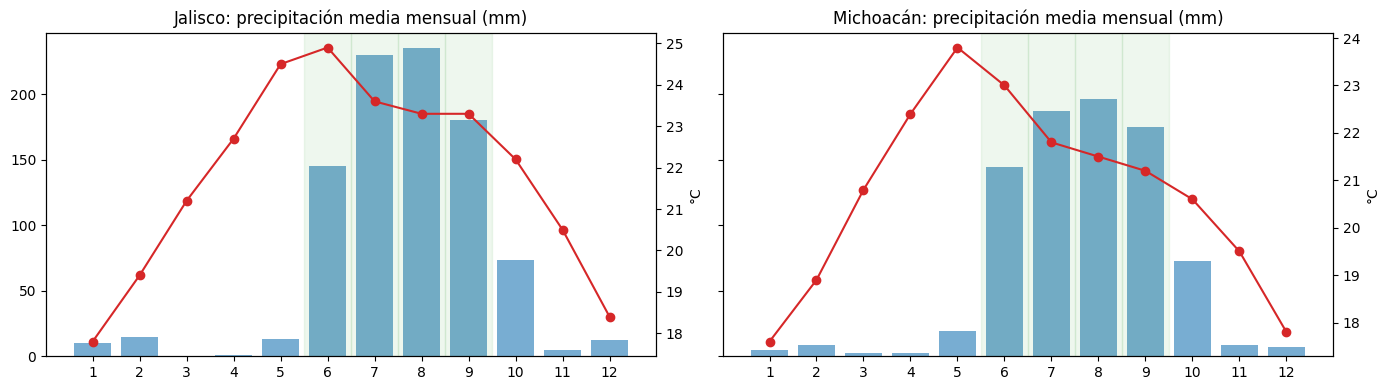

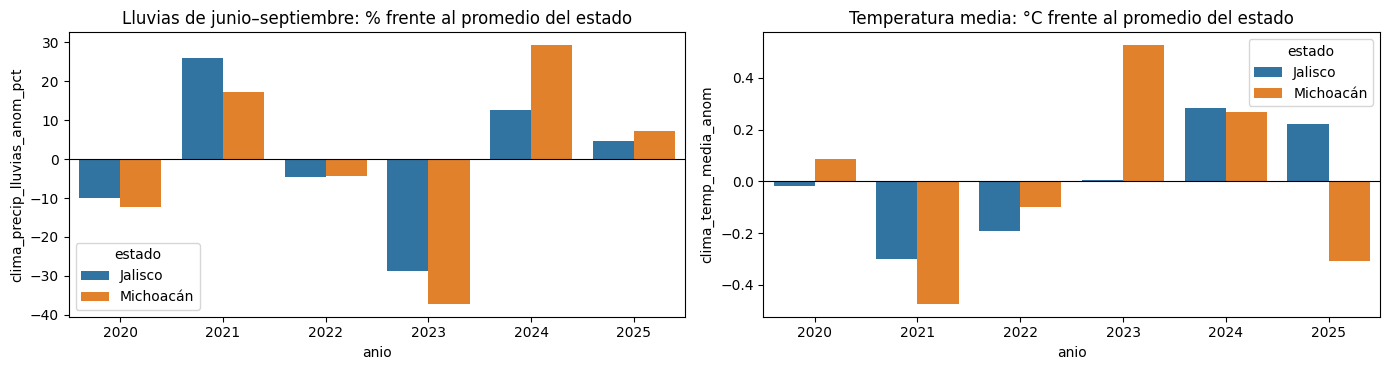

In [12]:
if df_clima_jm_mensual is not None:
    comp = df_clima_jm_mensual.merge(df_clima_jm_anual[['clave_estado', 'anio']], on=['clave_estado', 'anio'])
    clim = (comp.groupby(['clave_estado', 'mes'])
                .agg(temp_media=('temp_media', 'mean'), temp_max=('temp_max', 'mean'), precip_mm=('precip_mm', 'mean'))
                .round(1).reset_index())
    clim['estado'] = clim['clave_estado'].map(ENTIDADES)
    display(clim.pivot(index='mes', columns='estado', values=['temp_media', 'precip_mm']))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
    for ax, (cve, g) in zip(axes, clim.groupby('clave_estado')):
        ax.bar(g['mes'], g['precip_mm'], color='tab:blue', alpha=0.6)
        ax.set_title(f"{ENTIDADES[cve]}: precipitación media mensual (mm)")
        ax.set_xticks(range(1, 13))
        for m in MESES_LLUVIA:
            ax.axvspan(m - 0.5, m + 0.5, color='tab:green', alpha=0.08)
        ax2 = ax.twinx(); ax2.plot(g['mes'], g['temp_media'], color='tab:red', marker='o'); ax2.set_ylabel('°C')
    plt.tight_layout(); plt.show()

    a = df_clima_jm_anual.assign(estado=lambda d: d['clave_estado'].map(ENTIDADES))
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
    sns.barplot(data=a, x='anio', y='clima_precip_lluvias_anom_pct', hue='estado', ax=axes[0])
    axes[0].set_title('Lluvias de junio–septiembre: % frente al promedio del estado'); axes[0].axhline(0, color='k', lw=0.8)
    sns.barplot(data=a, x='anio', y='clima_temp_media_anom', hue='estado', ax=axes[1])
    axes[1].set_title('Temperatura media: °C frente al promedio del estado'); axes[1].axhline(0, color='k', lw=0.8)
    plt.tight_layout(); plt.show()

### 8.0.1 ¿La sequía del monitor coincide con lo que midieron las estaciones?

El monitor de sequía (`Sequia.csv`) tiene historia desde 2003; el clima medido solo desde 2020. Si ambos coinciden en 2020–2026, hay base para usar el monitor como aproximación del clima en los años anteriores.

Como la lluvia y la sequía siguen el ciclo del año, se **quita el patrón estacional** (cada mes contra el promedio de ese mismo mes) antes de correlacionar. La sequía responde a la lluvia acumulada de varios meses, por eso se prueba también la lluvia de 3 meses.

In [13]:
if df_clima_jm_mensual is not None and df_sequia_mensual is not None:
    sq = (df_sequia_mensual.assign(clave_estado=lambda d: d['clave_mun'].str[:2])
          .groupby(['clave_estado', 'anio', 'mes'], as_index=False)['sequia_sev_media'].mean()
          .rename(columns={'sequia_sev_media': 'sequia_estado'}))
    x = (df_clima_jm_mensual.sort_values(['clave_estado', 'anio', 'mes'])
         .merge(sq, on=['clave_estado', 'anio', 'mes'], how='inner'))
    x['precip_3m'] = x.groupby('clave_estado')['precip_mm'].transform(lambda s: s.rolling(3).sum())
    for col in ['sequia_estado', 'precip_mm', 'precip_3m', 'temp_max']:
        x[col + '_dsz'] = x[col] - x.groupby(['clave_estado', 'mes'])[col].transform('mean')    # sin estacionalidad
    filas = []
    for cve, g in x.groupby('clave_estado'):
        g = g.dropna(subset=['sequia_estado_dsz', 'precip_3m_dsz'])
        for nombre, col in [('precipitación del mes', 'precip_mm_dsz'), ('precipitación de 3 meses', 'precip_3m_dsz'),
                            ('temperatura máxima', 'temp_max_dsz')]:
            rho, p = stats.spearmanr(g['sequia_estado_dsz'], g[col])
            filas.append({'estado': ENTIDADES[cve], 'comparación con la severidad de sequía': nombre,
                          'n_meses': len(g), 'rho_Spearman': round(rho, 2), 'p': round(p, 4)})
    display(pd.DataFrame(filas))
    print('Lectura: si la sequía del monitor es una buena aproximación, rho debe ser negativo con la lluvia y positivo con la temperatura.')
else:
    print('Se necesitan el clima medido y la sequía mensual para este contraste.')

,estado,comparación con la severidad de sequía,n_meses,rho_Spearman,p
0,Jalisco,precipitación del mes,52,-0.19,0.1678
1,Jalisco,precipitación de 3 meses,52,-0.42,0.0022
2,Jalisco,temperatura máxima,52,0.26,0.0666
3,Michoacán,precipitación del mes,52,-0.16,0.2666
4,Michoacán,precipitación de 3 meses,52,-0.42,0.0020
5,Michoacán,temperatura máxima,52,0.43,0.0016


Lectura: si la sequía del monitor es una buena aproximación, rho debe ser negativo con la lluvia y positivo con la temperatura.


## 8.1 Mercado y exportaciones

Se incorporan tres archivos. **Ojo con lo que es cada uno:**

| Archivo | Qué contiene realmente |
|---|---|
| `Destinos-comerciales-2022.csv` | Comercio **mundial** de aguacate en 2022 visto desde quien **compra** (valor por país importador). No es "de México a dónde". |
| `Origenes-comerciales-2022.csv` | El mismo comercio mundial visto desde quien **vende** (valor por país exportador). México aparece aquí como un exportador más. |
| `mexicos-exports-to-world-in-2025-by-importer_080440.csv` | **Sí es de México a dónde**: exportaciones mexicanas de aguacate (HS 080440) en 2025 por país comprador, con valor, toneladas, valor unitario y participación. |

Los dos primeros suman casi lo mismo (≈ 7,533 millones de USD), lo que confirma que son dos vistas del mismo mercado mundial. Los archivos no nombran el producto ni la moneda: por la lista de países y porque México aparece como primer exportador, se asume **aguacate fresco y valores en USD** (conviene verificarlo en la fuente de descarga).

**Limitación para el modelo:** son fotos de un solo año (2022 y 2025). Una variable que no cambia entre filas no puede explicar por qué cambia la oferta o el precio, así que **no entran al modelo**; sirven para entender el mercado, medir la dependencia de EE.UU. y comparar el precio al productor contra el de exportación.

Comercio mundial 2022: importadores suman 7,533 M USD | exportadores suman 7,533 M USD (diferencia 0.0019%)

Quién VENDE (exportadores):


,pais,valor_usd,participacion_pct,crec_vs_anio_previo
121,México,3.409720e+09,45.262,-0.050
144,Perú,1.078769e+09,14.320,-0.109
95,Países Bajos,6.383631e+08,8.474,-0.120
79,España,4.136100e+08,5.490,-0.098
141,Chile,2.949868e+08,3.916,-0.036
48,Israel,2.578546e+08,3.423,-0.021
142,Colombia,2.080933e+08,2.762,-0.144
13,Kenia,1.875377e+08,2.489,0.173
14,Marruecos,1.574463e+08,2.090,0.464
31,Sudáfrica,1.481626e+08,1.967,0.001


Quién COMPRA (importadores):


,pais,valor_usd,participacion_pct,crec_vs_anio_previo
155,Estados Unidos,3.294910e+09,43.739,0.068
117,Países Bajos,8.341707e+08,11.073,-0.112
101,Francia,5.363584e+08,7.120,-0.044
98,España,3.233600e+08,4.293,-0.279
136,Canadá,2.861771e+08,3.799,-0.236
102,Reino Unido,2.602236e+08,3.454,-0.108
96,Alemania,2.301583e+08,3.055,-0.118
58,Japón,1.476011e+08,1.959,-0.309
118,Noruega,1.163842e+08,1.545,-0.190
109,Italia,1.051838e+08,1.396,-0.038


México vende 45.3% del comercio mundial; Estados Unidos compra 43.7%.
Concentración (HHI): exportadores 2,411 | importadores 2,160

Exportaciones de México 2025: 3.97 mil millones USD | 1,219,971 t | valor unitario 3,251 USD/t


,socio,valor_kusd,toneladas,valor_unitario_usd_t,participacion_valor_pct,mx_en_importaciones_del_socio_pct,crec_valor_5a_pct,crec_valor_2a_pct
1,Estados Unidos de América,3441929,1053721.0,3266.45,86.78,87.12,9.0,4.0
2,Canadá,268853,80427.0,3342.82,6.78,86.62,3.0,4.0
3,Japón,96157,34010.0,2827.32,2.42,64.11,-5.0,-11.0
4,El Salvador,57538,18239.0,3154.67,1.45,91.78,21.0,13.0
5,Honduras,49497,14839.0,3335.60,1.25,97.12,17.0,13.0
6,Costa Rica,19061,6227.0,3061.02,0.48,46.51,NaN,-25.0
7,España,10540,4636.0,2273.51,0.27,1.42,-48.0,-18.0
8,Emiratos Árabes Unidos,9079,2998.0,3028.35,0.23,13.77,6.0,-15.0
9,Kuwait,4595,1374.0,3344.25,0.12,62.72,55.0,25.0
10,Países Bajos,2493,1074.0,2321.23,0.06,0.22,-43.0,-39.0


EE.UU. recibe 86.8% del valor; México abastece 87.1% de lo que EE.UU. importa. HHI de destinos de México: 7,586
Valor unitario: EE.UU. 3,266 USD/t vs Europa (ES/NL/FR) 2,341 USD/t en promedio. Los volúmenes a Europa son pequeños (6,300 t), así que la comparación es una referencia, no un precio de mercado.


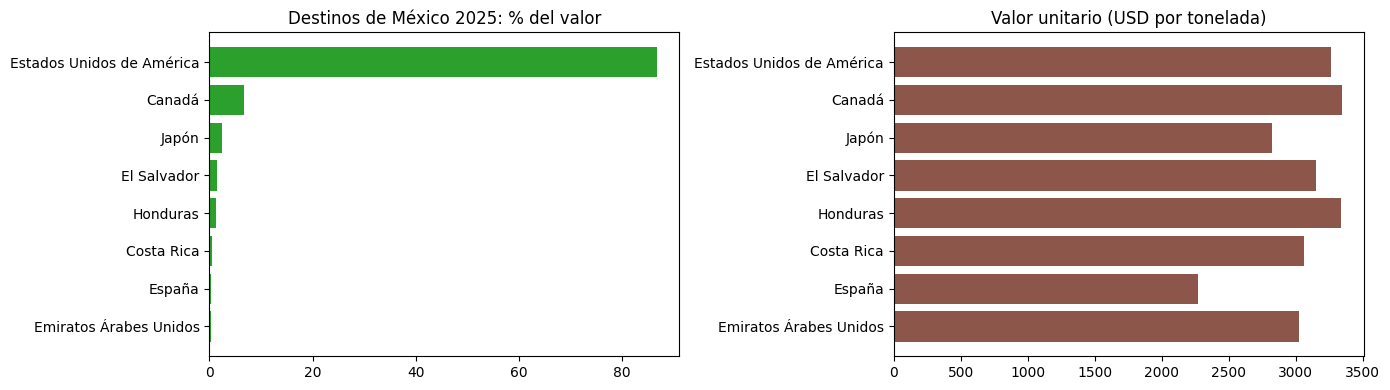

In [14]:
def leer_comercio(clave):
    ruta = ruta_local(clave)
    if ruta is None:
        print(f'AVISO: no encontré {ARCHIVOS[clave]["destino"]}.')
        return None
    d = pd.read_csv(ruta, encoding='utf-8-sig')
    d = d.rename(columns={'Continent': 'continente', 'Country': 'pais', 'Year': 'anio', 'Trade Value': 'valor_usd',
                          'Trade Value Growth': 'crec_vs_anio_previo', 'Trade Value Growth Value': 'crec_valor_usd'})
    d['valor_usd'] = pd.to_numeric(d['valor_usd'], errors='coerce')
    d['participacion_pct'] = d['valor_usd'] / d['valor_usd'].sum() * 100
    return d[['continente', 'pais', 'anio', 'valor_usd', 'participacion_pct', 'crec_vs_anio_previo']]


def leer_exportaciones_mx():
    ruta = ruta_local('exportaciones_mx')
    if ruta is None:
        print(f'AVISO: no encontré {ARCHIVOS["exportaciones_mx"]["destino"]}.')
        return None
    d = pd.read_csv(ruta, encoding='utf-8-sig')
    d.columns = [str(c).strip() for c in d.columns]
    ren = {'partnerLabel': 'socio', 'Value (kUSD)': 'valor_kusd', 'Quantity': 'toneladas',
           'Unit Value': 'valor_unitario_usd_t', 'Share (%)': 'participacion_valor_pct',
           'Share Partner Country (%)': 'mx_en_importaciones_del_socio_pct',
           'Growth Value 5Y (%)': 'crec_valor_5a_pct', 'Growth Value 2Y (%)': 'crec_valor_2a_pct'}
    d = d.rename(columns=ren)
    cols = list(ren.values())
    for c in cols[1:]:
        d[c] = pd.to_numeric(d[c], errors='coerce')
    d['anio'] = 2025                                   # el nombre del archivo indica 2025
    return d[['socio', 'anio'] + cols[1:]]


df_destinos = leer_comercio('destinos')
df_origenes = leer_comercio('origenes')
df_exportaciones_mx = leer_exportaciones_mx()


def hhi(shares_pct):
    '''Índice Herfindahl-Hirschman en escala 0–10,000. Más de 2,500 suele considerarse mercado concentrado (convención, no ley).'''
    s = np.asarray(shares_pct, float)
    return float((s ** 2).sum())


if df_destinos is not None and df_origenes is not None:
    print(f"Comercio mundial 2022: importadores suman {df_destinos.valor_usd.sum() / 1e6:,.0f} M USD | "
          f"exportadores suman {df_origenes.valor_usd.sum() / 1e6:,.0f} M USD "
          f"(diferencia {abs(df_destinos.valor_usd.sum() / df_origenes.valor_usd.sum() - 1):.4%})")
    top_o = df_origenes.sort_values('valor_usd', ascending=False).head(10)
    top_d = df_destinos.sort_values('valor_usd', ascending=False).head(10)
    print('\nQuién VENDE (exportadores):'); display(top_o[['pais', 'valor_usd', 'participacion_pct', 'crec_vs_anio_previo']].round(3))
    print('Quién COMPRA (importadores):'); display(top_d[['pais', 'valor_usd', 'participacion_pct', 'crec_vs_anio_previo']].round(3))
    mx = df_origenes.loc[df_origenes['pais'] == 'México', 'participacion_pct']
    us = df_destinos.loc[df_destinos['pais'] == 'Estados Unidos', 'participacion_pct']
    print(f"México vende {mx.iloc[0]:.1f}% del comercio mundial; Estados Unidos compra {us.iloc[0]:.1f}%.")
    print(f"Concentración (HHI): exportadores {hhi(df_origenes.participacion_pct):,.0f} | importadores {hhi(df_destinos.participacion_pct):,.0f}")

if df_exportaciones_mx is not None:
    mxd = df_exportaciones_mx[df_exportaciones_mx['socio'] != 'Mundo'].copy()
    mundo = df_exportaciones_mx[df_exportaciones_mx['socio'] == 'Mundo'].iloc[0]
    print(f"\nExportaciones de México 2025: {mundo.valor_kusd / 1e6:,.2f} mil millones USD | {mundo.toneladas:,.0f} t | "
          f"valor unitario {mundo.valor_unitario_usd_t:,.0f} USD/t")
    display(mxd.sort_values('valor_kusd', ascending=False)
            [['socio', 'valor_kusd', 'toneladas', 'valor_unitario_usd_t', 'participacion_valor_pct',
              'mx_en_importaciones_del_socio_pct', 'crec_valor_5a_pct', 'crec_valor_2a_pct']].round(2))
    us_row = mxd[mxd['socio'].str.contains('Estados Unidos', na=False)].iloc[0]
    print(f"EE.UU. recibe {us_row.participacion_valor_pct:.1f}% del valor; México abastece {us_row.mx_en_importaciones_del_socio_pct:.1f}% "
          f"de lo que EE.UU. importa. HHI de destinos de México: {hhi(mxd.participacion_valor_pct):,.0f}")
    eu = mxd[mxd['socio'].isin(['España', 'Países Bajos', 'Francia'])]
    if len(eu):
        print(f"Valor unitario: EE.UU. {us_row.valor_unitario_usd_t:,.0f} USD/t vs Europa (ES/NL/FR) "
              f"{eu.valor_unitario_usd_t.mean():,.0f} USD/t en promedio. Los volúmenes a Europa son pequeños "
              f"({eu.toneladas.sum():,.0f} t), así que la comparación es una referencia, no un precio de mercado.")
    g = mxd.sort_values('valor_kusd', ascending=False).head(8)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].barh(g['socio'][::-1], g['participacion_valor_pct'][::-1], color='tab:green'); axes[0].set_title('Destinos de México 2025: % del valor')
    axes[1].barh(g['socio'][::-1], g['valor_unitario_usd_t'][::-1], color='tab:brown'); axes[1].set_title('Valor unitario (USD por tonelada)')
    plt.tight_layout(); plt.show()

## 9. Cobertura de las fuentes
 Si una fuente tiene menos de 3 años, no sirve para entrenar y el modelo la descarta.

In [15]:
def resumen_cobertura(fuente, df, col_entidad):
    if df is None or len(df) == 0:
        return {'fuente': fuente, 'año_min': None, 'año_max': None, 'entidades': 0,
                'nota': 'SIN DATOS: no entra al modelo'}
    a_min, a_max = int(df['anio'].min()), int(df['anio'].max())
    nota = 'ok' if (a_max - a_min) >= 2 else 'pocos años: no entrena'
    ent = df[col_entidad].nunique() if col_entidad else 'nacional'
    return {'fuente': fuente, 'año_min': a_min, 'año_max': a_max, 'entidades': ent, 'nota': nota}


cobertura = pd.DataFrame([
    resumen_cobertura('SIAP municipal (oferta y precio)', df_oferta, 'clave_mun'),
    resumen_cobertura('Sequía (municipal)', df_sequia_anual, 'clave_mun'),
    resumen_cobertura('Ciclones (estado)', ciclon_anual, 'clave_estado'),
    resumen_cobertura('Desastres EM-DAT (estado)', desastres_anual, 'clave_estado'),
    resumen_cobertura('Tipo de cambio (nacional)', df_tc_anual, None),
    resumen_cobertura('Clima Jalisco y Michoacán (estado)', df_clima_jm_anual, 'clave_estado'),
    resumen_cobertura('Mercado mundial: destinos 2022', df_destinos, None),
    resumen_cobertura('Mercado mundial: orígenes 2022', df_origenes, None),
    resumen_cobertura('Exportaciones de México 2025', df_exportaciones_mx, None),
]).astype({'año_min': 'Int64', 'año_max': 'Int64'})
display(cobertura)

,fuente,año_min,año_max,entidades,nota
0,SIAP municipal (oferta y precio),2003,2024,158,ok
1,Sequía (municipal),2003,2026,238,ok
2,Ciclones (estado),1945,2026,2,ok
3,Desastres EM-DAT (estado),2002,2024,2,ok
4,Tipo de cambio (nacional),2022,2026,nacional,ok
5,Clima Jalisco y Michoacán (estado),2020,2025,2,ok
6,Mercado mundial: destinos 2022,2022,2022,nacional,pocos años: no entrena
7,Mercado mundial: orígenes 2022,2022,2022,nacional,pocos años: no entrena
8,Exportaciones de México 2025,2025,2025,nacional,pocos años: no entrena


## 10. Panel municipio × año

Une la oferta del SIAP con sequía, ciclones, desastres, delitos y tipo de cambio del mismo año. Las variables de entrada son de **t** y el objetivo es de **t+1**, así que el modelo nunca ve información futura.

In [16]:
panel = df_oferta.merge(df_sequia_anual, on=['clave_mun', 'anio'], how='left')
panel['clave_estado'] = panel['clave_mun'].str[:2]
panel = panel.merge(ciclon_anual, on=['clave_estado', 'anio'], how='left')
panel = panel.merge(desastres_anual, on=['clave_estado', 'anio'], how='left')
panel[['ciclon_meses', 'desastre_eventos_anual']] = panel[['ciclon_meses', 'desastre_eventos_anual']].fillna(0)
if df_tc_anual is not None:
    panel = panel.merge(df_tc_anual, on='anio', how='left')
if df_clima_jm_anual is not None:                        # NUEVO: clima medido de Jalisco y Michoacán (llave: estado + año)
    panel = panel.merge(df_clima_jm_anual, on=['clave_estado', 'anio'], how='left')

panel = panel.sort_values(['clave_mun', 'anio']).reset_index(drop=True)

# Rezagos y objetivos. Con LAGS_POR_ANIO = True se usa el AÑO CALENDARIO anterior/siguiente; con False, la fila anterior/siguiente
# (como en la entrega anterior), que se equivoca si un municipio salta años.
LAGS_POR_ANIO = True
g = panel.groupby('clave_mun')
desplazado = {'volumen_lag1': g['volumen'].shift(1), 'precio_lag1': g['precio_kg'].shift(1),
              'y_volumen_sig': g['volumen'].shift(-1), 'y_precio_sig': g['precio_kg'].shift(-1)}
if LAGS_POR_ANIO:
    base_ = panel[['clave_mun', 'anio', 'volumen', 'precio_kg']]
    prev_ = base_.assign(anio=base_['anio'] + 1).rename(columns={'volumen': 'volumen_lag1', 'precio_kg': 'precio_lag1'})
    sig_ = base_.assign(anio=base_['anio'] - 1).rename(columns={'volumen': 'y_volumen_sig', 'precio_kg': 'y_precio_sig'})
    panel = (panel.merge(prev_, on=['clave_mun', 'anio'], how='left')
                  .merge(sig_, on=['clave_mun', 'anio'], how='left'))
    dif = {k: int((panel[k].fillna(-1) != v.reset_index(drop=True).fillna(-1)).sum()) for k, v in desplazado.items()}
    print('Filas donde el rezago por año calendario difiere del de "fila anterior":', dif)
else:
    for k, v in desplazado.items():
        panel[k] = v
panel['periodo_obj'] = panel['anio'] + 1
print('Panel municipio × año:', panel.shape, '| municipios:', panel['clave_mun'].nunique())
display(panel.head())


Filas donde el rezago por año calendario difiere del de "fila anterior": {'volumen_lag1': 13, 'precio_lag1': 12, 'y_volumen_sig': 13, 'y_precio_sig': 7}
Panel municipio × año: (2594, 30) | municipios: 158


,clave_mun,anio,volumen,cosechada_ha,sembrada_ha,valor_miles,rendimiento_ton_ha,precio_kg,sequia_sev_media_anual,sequia_meses_severos,clave_estado,ciclon_meses,desastre_eventos_anual,tipo_cambio_anual,clima_temp_media,clima_temp_max_media,clima_temp_min_media,clima_tmax_pico,clima_precip_anual,clima_precip_lluvias,clima_precip_secas,clima_amplitud,clima_temp_media_anom,clima_precip_lluvias_anom_pct,clima_precip_anual_anom_pct,volumen_lag1,precio_lag1,y_volumen_sig,y_precio_sig,periodo_obj
0,14001,2012,0.00,0.0,29.0,0.00,NaN,NaN,0.5000,0,14,3,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,493.00,17920.010000,2013
1,14001,2013,493.00,29.0,29.0,8834564.93,17.000,17920.010000,0.1250,0,14,4,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,348.00,19733.330000,2014
2,14001,2014,348.00,29.0,29.0,6867198.84,12.000,19733.330000,0.2500,0,14,5,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,493.00,17920.010000,631.38,17527.659999,2015
3,14001,2015,631.38,60.0,80.0,11066613.97,10.523,17527.659999,0.0000,0,14,4,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,348.00,19733.330000,904.80,17810.150000,2016
4,14001,2016,904.80,80.0,105.4,16114623.72,11.310,17810.150000,0.1875,0,14,4,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,631.38,17527.659999,1222.64,22365.930004,2017


## 11. Modelos de oferta y precio anual (validación temporal)

Dos modelos con las mismas variables de entrada: uno predice la **oferta** del año siguiente y otro el **precio medio rural** del año siguiente. Cada uno se compara contra la **persistencia** (repetir el valor de este año). La división es temporal: entrenamiento antes que validación, y validación antes que prueba. Las variables con menos de 50% de cobertura se descartan solas.

> **Nota de esta versión.** Esta sección se conserva como **línea base de la entrega anterior** (Random Forest con las 10 variables, partición 70/15/15). Ya no incluye el clima de EE.UU. (la cobertura mínima lo descartaba de todos modos). Los modelos nuevos están en las secciones 15 a 18.

Variables descartadas por cobertura insuficiente: ['tipo_cambio_anual']
Variables de los modelos: ['volumen', 'volumen_lag1', 'precio_kg', 'precio_lag1', 'rendimiento_ton_ha', 'sembrada_ha', 'sequia_sev_media_anual', 'sequia_meses_severos', 'ciclon_meses', 'desastre_eventos_anual']
--- Modelo 1: oferta (ton) año t → t+1: 2109 filas usables de 2594
Partición temporal: entrenamiento 2005–2018 | validación 2019–2021 | prueba 2022–2024


,validación,prueba
MAPE modelo (%),25.60,16.20
MAPE persistencia (%),17.84,10.11


,importancia
sembrada_ha,0.435828
volumen,0.417072
volumen_lag1,0.138852
rendimiento_ton_ha,0.003736
precio_kg,0.001302
sequia_sev_media_anual,0.001289
precio_lag1,0.000960
ciclon_meses,0.000477
sequia_meses_severos,0.000437
desastre_eventos_anual,0.000046


--- Modelo 2: precio medio rural ($/ton) año t → t+1: 2097 filas usables de 2594
Partición temporal: entrenamiento 2005–2018 | validación 2019–2021 | prueba 2022–2024


,validación,prueba
MAPE modelo (%),15.24,19.14
MAPE persistencia (%),18.34,18.53


,importancia
precio_kg,0.481329
precio_lag1,0.241484
rendimiento_ton_ha,0.067230
sequia_sev_media_anual,0.055514
desastre_eventos_anual,0.035888
ciclon_meses,0.033376
sembrada_ha,0.028283
volumen_lag1,0.024492
volumen,0.022576
sequia_meses_severos,0.009829


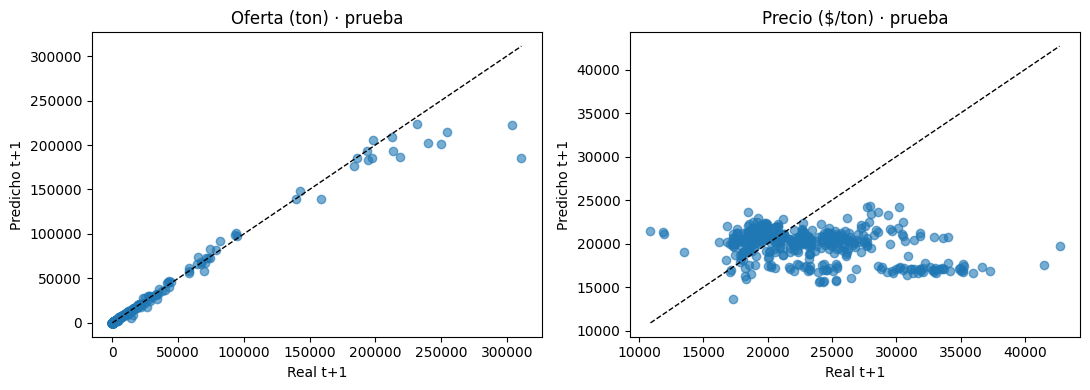

In [17]:
def cols_utilizables(df, cols, target):
    d = df[df[target].notna()]
    ok, descartadas = [], []
    for c in cols:
        if c in d.columns and d[c].notna().mean() >= MIN_COBERTURA:
            ok.append(c)
        else:
            descartadas.append(c)
    if descartadas:
        print('Variables descartadas por cobertura insuficiente:', descartadas)
    return ok


def split_por_periodo(df, col_periodo, frac=(0.70, 0.15, 0.15)):
    periodos = sorted(df[col_periodo].unique())
    n = len(periodos)
    n_tr = max(1, int(round(n * frac[0])))
    n_va = max(1, int(round(n * frac[1])))
    p_tr, p_va, p_te = periodos[:n_tr], periodos[n_tr:n_tr + n_va], periodos[n_tr + n_va:]
    if not p_te:
        raise ValueError('No hay periodos suficientes para una prueba fuera de muestra')
    print(f'Partición temporal: entrenamiento {p_tr[0]}–{p_tr[-1]} | '
          f'validación {p_va[0]}–{p_va[-1]} | prueba {p_te[0]}–{p_te[-1]}')
    return (df[df[col_periodo].isin(p_tr)], df[df[col_periodo].isin(p_va)],
            df[df[col_periodo].isin(p_te)])


def evaluar_modelo(df, features, target, baseline, periodo_col, nombre):
    d = df.dropna(subset=[target, baseline] + features).copy()
    print(f'--- {nombre}: {len(d)} filas usables de {len(df)}')
    tr, va, te = split_por_periodo(d, periodo_col)
    rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.6,
                               random_state=42, n_jobs=-1)
    rf.fit(tr[features], tr[target])
    m_va = {'MAPE modelo (%)': mape(va[target], rf.predict(va[features])),
            'MAPE persistencia (%)': mape(va[target], va[baseline])}
    trva = pd.concat([tr, va])
    rf.fit(trva[features], trva[target])               # reentrenamiento para la prueba
    m_te = {'MAPE modelo (%)': mape(te[target], rf.predict(te[features])),
            'MAPE persistencia (%)': mape(te[target], te[baseline])}
    resumen = pd.DataFrame({'validación': m_va, 'prueba': m_te}).round(2)
    display(resumen)
    imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
    return rf, resumen, imp, te


BASE_FEATS = (['volumen', 'volumen_lag1', 'precio_kg', 'precio_lag1', 'rendimiento_ton_ha', 'sembrada_ha']
              + ['sequia_sev_media_anual', 'sequia_meses_severos', 'ciclon_meses', 'desastre_eventos_anual']
              + ['tipo_cambio_anual'])
feats_modelos = cols_utilizables(panel, BASE_FEATS, 'y_volumen_sig')
print('Variables de los modelos:', feats_modelos)

rf_vol, res_vol, imp_vol, te_vol = evaluar_modelo(
    panel, feats_modelos, 'y_volumen_sig', 'volumen', 'periodo_obj',
    'Modelo 1: oferta (ton) año t → t+1')
display(imp_vol.rename('importancia').to_frame())

rf_pre, res_pre, imp_pre, te_pre = evaluar_modelo(
    panel, feats_modelos, 'y_precio_sig', 'precio_kg', 'periodo_obj',
    'Modelo 2: precio medio rural ($/ton) año t → t+1')
display(imp_pre.rename('importancia').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, rf_, te_, tgt, tit in [(axes[0], rf_vol, te_vol, 'y_volumen_sig', 'Oferta (ton)'),
                               (axes[1], rf_pre, te_pre, 'y_precio_sig', 'Precio ($/ton)')]:
    ax.scatter(te_[tgt], rf_.predict(te_[feats_modelos]), alpha=0.6)
    lim = [te_[tgt].min(), te_[tgt].max()]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlabel('Real t+1'); ax.set_ylabel('Predicho t+1'); ax.set_title(tit + ' · prueba')
plt.tight_layout()
plt.show()

## 12. Índices de riesgo y salidas por perfil

- **Índice climático (IRC):** promedio de los z-scores de sequía, meses con ciclón y eventos de desastre. Compara municipios entre sí en el mismo año.
- **Volatilidad (CV):** coeficiente de variación de la oferta histórica de cada municipio.
- **Probabilidad de caída de precio:** fracción de los árboles del modelo de precio que predicen un precio menor al actual. Es una aproximación, no una probabilidad calibrada.
- **Precio en dólares (exportador):** precio esperado en MXN/kg dividido entre el tipo de cambio promedio del año de referencia.

El índice de seguridad solo se calcula si hay historia de delitos.

In [18]:
ref_anio = int(panel['anio'].max())                 # último año con oferta, desde el que se pronostica el siguiente
ref = panel[panel['anio'] == ref_anio].dropna(subset=feats_modelos).copy()
ref['municipio'] = ref['clave_mun'].map(nombres_mun.set_index('clave_mun')['NOMBRE_MUN']) \
    if 'NOMBRE_MUN' in nombres_mun.columns else ref['clave_mun']
ref['estado'] = ref['clave_mun'].str[:2].map(ENTIDADES)

ref['volumen_esperado_t+1'] = rf_vol.predict(ref[feats_modelos])
ref['precio_esperado_t+1'] = rf_pre.predict(ref[feats_modelos])
arboles = np.stack([t.predict(ref[feats_modelos]) for t in rf_pre.estimators_])
ref['prob_caida_precio'] = (arboles < ref['precio_kg'].values).mean(axis=0)

ref['IRC'] = pd.concat([zscore(ref['sequia_sev_media_anual']),
                        zscore(ref['ciclon_meses']),
                        zscore(ref['desastre_eventos_anual'])], axis=1).mean(axis=1)

cv = (df_oferta.groupby('clave_mun')['volumen']
               .agg(lambda s: s.std() / s.mean() if s.mean() else np.nan).rename('cv_volumen'))
ref = ref.merge(cv, left_on='clave_mun', right_index=True, how='left')

tc_ref = df_tc_anual.set_index('anio')['tipo_cambio_anual'].get(ref_anio, np.nan) if df_tc_anual is not None else np.nan
print(f'Año de referencia: {ref_anio} → pronóstico para {ref_anio + 1} | tipo de cambio {ref_anio}: {tc_ref}')

# ----- PRODUCTOR -----
productor = (ref[['municipio', 'estado', 'volumen_esperado_t+1', 'precio_esperado_t+1',
                  'prob_caida_precio', 'IRC']]
             .sort_values('volumen_esperado_t+1', ascending=False).round(3))
print('\n=== PRODUCTOR: oferta y precio esperados, probabilidad de caída y riesgo climático ===')
display(productor.head(15))

# ----- CLIMA MEDIDO EN LA ENTIDAD (año de referencia vs promedio de los años completos 2020–2025) -----
if df_clima_jm_anual is not None and ref_anio in set(df_clima_jm_anual['anio']):
    cj = df_clima_jm_anual[df_clima_jm_anual['anio'] == ref_anio].copy()
    cj['estado'] = cj['clave_estado'].map(ENTIDADES)
    print(f'\n=== CLIMA MEDIDO {ref_anio} por entidad (anomalía frente al promedio de los años completos disponibles; ojo: solo 6 años de historia) ===')
    display(cj[['estado', 'clima_temp_media', 'clima_temp_media_anom', 'clima_precip_lluvias',
                'clima_precip_lluvias_anom_pct']].round(1))
else:
    print(f'\nSin clima medido completo para {ref_anio}: no se muestra la anomalía.')

# ----- EXPORTADOR -----
exportador = (ref.groupby('estado', as_index=False)
                 .agg(oferta_esperada_ton=('volumen_esperado_t+1', 'sum'),
                      precio_esperado_mxn_ton=('precio_esperado_t+1', 'mean')))
exportador['precio_esperado_usd_ton'] = exportador['precio_esperado_mxn_ton'] / tc_ref
print('\n=== EXPORTADOR: oferta esperada y precio en dólares (proxy por entidad) ===')
display(exportador.round(2))
if df_exportaciones_mx is not None and tc_ref == tc_ref:       # tc_ref == tc_ref: descarta NaN
    uv_mundo = float(df_exportaciones_mx.loc[df_exportaciones_mx['socio'] == 'Mundo', 'valor_unitario_usd_t'].iloc[0])
    exportador['% del valor unitario de exportación 2025'] = exportador['precio_esperado_usd_ton'] / uv_mundo * 100
    print(f'Referencia: México exportó a {uv_mundo:,.0f} USD/t en 2025. La última columna dice qué parte de ese valor '
          f'unitario equivale al precio esperado al productor. Es una referencia aproximada: años distintos (precio esperado 2025, '
          f'exportación 2025 observada, tipo de cambio de {ref_anio}) y eslabones distintos de la cadena (el valor de exportación '
          f'incluye empaque, logística y margen).')
    display(exportador.round(2))

# ----- COMERCIALIZADOR / CONSUMIDOR -----
comercial = (ref.groupby('estado', as_index=False)
                .agg(precio_actual=('precio_kg', 'mean'), precio_esperado=('precio_esperado_t+1', 'mean')))
comercial['variacion_esperada_pct'] = (comercial['precio_esperado'] / comercial['precio_actual'] - 1) * 100
print('\n=== COMERCIALIZADOR / CONSUMIDOR: variación esperada del precio por entidad ===')
display(comercial.round(2))

# ----- INVERSIONISTA -----
inversionista = (ref[['municipio', 'estado', 'IRC', 'cv_volumen',
                      'sequia_sev_media_anual', 'ciclon_meses']]
                 .sort_values('IRC', ascending=False).round(3))
print('\n=== INVERSIONISTA: riesgo climático, volatilidad y exposición a sequía ===')
display(inversionista.head(15))

Año de referencia: 2024 → pronóstico para 2025 | tipo de cambio 2024: 18.31974774590164

=== PRODUCTOR: oferta y precio esperados, probabilidad de caída y riesgo climático ===


,municipio,estado,volumen_esperado_t+1,precio_esperado_t+1,prob_caida_precio,IRC
2217,Tancítaro,Michoacán,218722.680,20045.034,0.312,0.448
1548,Ario,Michoacán,210152.622,18766.923,0.946,0.561
2506,Uruapan,Michoacán,209928.067,20002.137,0.568,0.561
2151,Salvador Escalante,Michoacán,199568.716,18812.220,0.956,0.533
2195,Tacámbaro,Michoacán,188826.186,18607.470,0.948,0.618
2038,Peribán,Michoacán,142901.818,20820.932,0.238,0.533
1939,Nuevo Parangaricutiro,Michoacán,100422.251,20304.047,0.512,0.448
2120,Los Reyes,Michoacán,94115.878,20168.091,0.284,0.618
2420,Turicato,Michoacán,73532.633,18698.304,0.944,0.730
347,Zapotlán el Grande,Jalisco,71723.984,20954.265,0.994,-0.446



=== CLIMA MEDIDO 2024 por entidad (anomalía frente al promedio de los años completos disponibles; ojo: solo 6 años de historia) ===


,estado,clima_temp_media,clima_temp_media_anom,clima_precip_lluvias,clima_precip_lluvias_anom_pct
4,Jalisco,22.1,0.3,890.2,12.5
10,Michoacán,21.0,0.3,908.6,29.3



=== EXPORTADOR: oferta esperada y precio en dólares (proxy por entidad) ===


,estado,oferta_esperada_ton,precio_esperado_mxn_ton,precio_esperado_usd_ton
0,Jalisco,362162.63,19959.73,1089.52
1,Michoacán,1997131.61,18955.33,1034.69


... (2 outputs left out)


=== COMERCIALIZADOR / CONSUMIDOR: variación esperada del precio por entidad ===


,estado,precio_actual,precio_esperado,variacion_esperada_pct
0,Jalisco,23260.53,19959.73,-14.19
1,Michoacán,19489.16,18955.33,-2.74



=== INVERSIONISTA: riesgo climático, volatilidad y exposición a sequía ===


,municipio,estado,IRC,cv_volumen,sequia_sev_media_anual,ciclon_meses
1711,Hidalgo,Michoacán,0.927,0.508,3.125,2
2451,Tuzantla,Michoacán,0.899,0.924,3.062,2
2080,Queréndaro,Michoacán,0.899,1.275,3.062,2
2484,Tzitzio,Michoacán,0.899,0.567,3.062,2
1830,Jungapeo,Michoacán,0.843,0.387,2.938,2
2173,Susupuato,Michoacán,0.815,0.446,2.875,2
1808,Juárez,Michoacán,0.815,0.386,2.875,2
2442,Tuxpan,Michoacán,0.758,0.525,2.750,2
2420,Turicato,Michoacán,0.730,0.735,2.688,2
1908,Morelos,Michoacán,0.702,0.238,2.625,2


## 13. Estadística descriptiva de la base de datos

Se resumen las variables del panel (faltantes, sesgo, dispersión) para conocer los datos antes de modelar.

In [19]:
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
try:
    from xgboost import XGBRegressor
    HAY_XGB = True
except Exception:
    HAY_XGB = False

warnings.filterwarnings('ignore')
assert 'panel' in globals(), 'Falta `panel`: ejecuta primero las secciones 1 a 10.'

# ---------------- Configuración de las secciones 13 a 18 ----------------
SPLITS = [0.60, 0.70]              # particiones temporales que se comparan: 60/40 y 70/30
ALPHA = 0.05                       # nivel de significancia del ANOVA
ETA2_MIN = 0.01                    # tamaño de efecto mínimo (η² ≥ 0.01)
R_MAX = 0.90                       # dos columnas con |r| > 0.9 dicen casi lo mismo: se conserva la de mayor F
SEMILLA = 42
# Métrica con la que se elige el mejor modelo DENTRO del entrenamiento (validación hacia adelante):
#   'neg_root_mean_squared_error'         -> RMSE (la dominan los municipios grandes)
#   'neg_mean_absolute_percentage_error'  -> MAPE (el KPI del reto; trata igual a municipios grandes y chicos)
METRICA_SELECCION = 'neg_mean_absolute_percentage_error'

SALIDAS2 = DATA_DIR / 'salidas_evidencia2'
SALIDAS2.mkdir(parents=True, exist_ok=True)

panel['estado'] = panel['clave_estado'].map(ENTIDADES)

# El precio del panel está en PESOS POR TONELADA (mediana ≈ 16,000), aunque la columna se llame precio_kg
BASE_PRECIO = ['precio_kg', 'precio_lag1']
BASE_PROD = ['volumen', 'volumen_lag1', 'rendimiento_ton_ha', 'sembrada_ha']
BASE = BASE_PRECIO + BASE_PROD
CLIMA_ANUAL = ['sequia_sev_media_anual', 'sequia_meses_severos', 'ciclon_meses', 'desastre_eventos_anual']   # los de la entrega anterior
CLIMA_ESTACIONAL = ['sequia_secas', 'sequia_lluvias', 'sequia_max', 'sequia_lag1', 'sequia_cambio']          # nuevos (sección 14.6)
CLIMA_MEDIDO = ['clima_temp_media', 'clima_tmax_pico', 'clima_precip_lluvias', 'clima_precip_secas']          # solo 2020+
LOG_FEATS = ['volumen', 'volumen_lag1', 'sembrada_ha']          # muy sesgadas: entran en log1p
FACTORES = ['estado', 'periodo']                                 # factores de diagnóstico (no son columnas del modelo)

# objetivo (t+1) y la variable de hoy (t) que sirve de referencia de persistencia
OBJETIVOS = {'Oferta (ton)': ('y_volumen_sig', 'volumen'),
             'Precio (MXN/ton)': ('y_precio_sig', 'precio_kg')}
YLOG = {'Oferta (ton)': 'ly_vol', 'Precio (MXN/ton)': 'ly_pre'}


def mape_pct(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    m = y != 0
    return float(np.mean(np.abs((y[m] - yhat[m]) / y[m])) * 100)

Panel municipio × año: (2594, 31)
Años: 2003–2024 | municipios: 158 | estados: 2


,count,mean,std,min,25%,50%,75%,max,faltantes_%,cv,asimetria
volumen,2594.0,1.249606e+04,3.684130e+04,0.00,74.00,475.65,4208.48,3.111428e+05,0.00,2.95,4.07
cosechada_ha,2594.0,1.161090e+03,3.375400e+03,0.00,10.00,50.00,414.25,2.574000e+04,0.00,2.91,4.04
sembrada_ha,2594.0,1.246420e+03,3.473780e+03,0.25,18.00,67.00,557.50,2.581500e+04,0.00,2.79,3.95
valor_miles,2594.0,2.136337e+08,6.763158e+08,0.00,914122.70,7929004.91,61172696.61,6.103480e+09,0.00,3.17,4.86
rendimiento_ton_ha,2438.0,9.740000e+00,3.450000e+00,0.50,7.50,10.00,11.70,2.975000e+01,6.01,0.35,0.36
precio_kg,2438.0,1.592741e+04,6.640610e+03,1000.00,11013.94,16011.46,20675.91,4.268193e+04,6.01,0.42,0.26
sequia_sev_media_anual,2594.0,1.090000e+00,8.800000e-01,0.00,0.38,0.94,1.62,3.750000e+00,0.00,0.81,0.77
sequia_meses_severos,2594.0,1.250000e+00,2.020000e+00,0.00,0.00,0.00,2.00,8.000000e+00,0.00,1.61,1.60
ciclon_meses,2594.0,3.450000e+00,1.110000e+00,1.00,3.00,4.00,4.00,7.000000e+00,0.00,0.32,0.00
desastre_eventos_anual,2594.0,6.200000e-01,9.900000e-01,0.00,0.00,0.00,1.00,4.000000e+00,0.00,1.59,2.17


,municipios,filas,volumen_total,precio_medio,precio_desv
estado,,,,,
Jalisco,88,1448,2696123.0,16483.9,7058.4
Michoacán,70,1146,29718651.4,15253.8,6031.6


,municipios,volumen_total,precio_medio,sequia_media
anio,,,,
2003,78,805605.3,6029.6,0.1
2004,78,868303.1,6283.2,0.1
2005,84,901009.1,6993.4,0.6
2006,89,1009787.5,7304.6,1.4
2007,95,1016266.7,9439.8,1.4
2008,100,1035759.8,10042.0,2.0
2009,105,1097285.1,11527.7,2.1
2010,111,980929.1,12430.7,0.0
2011,111,1130085.8,13663.9,1.8


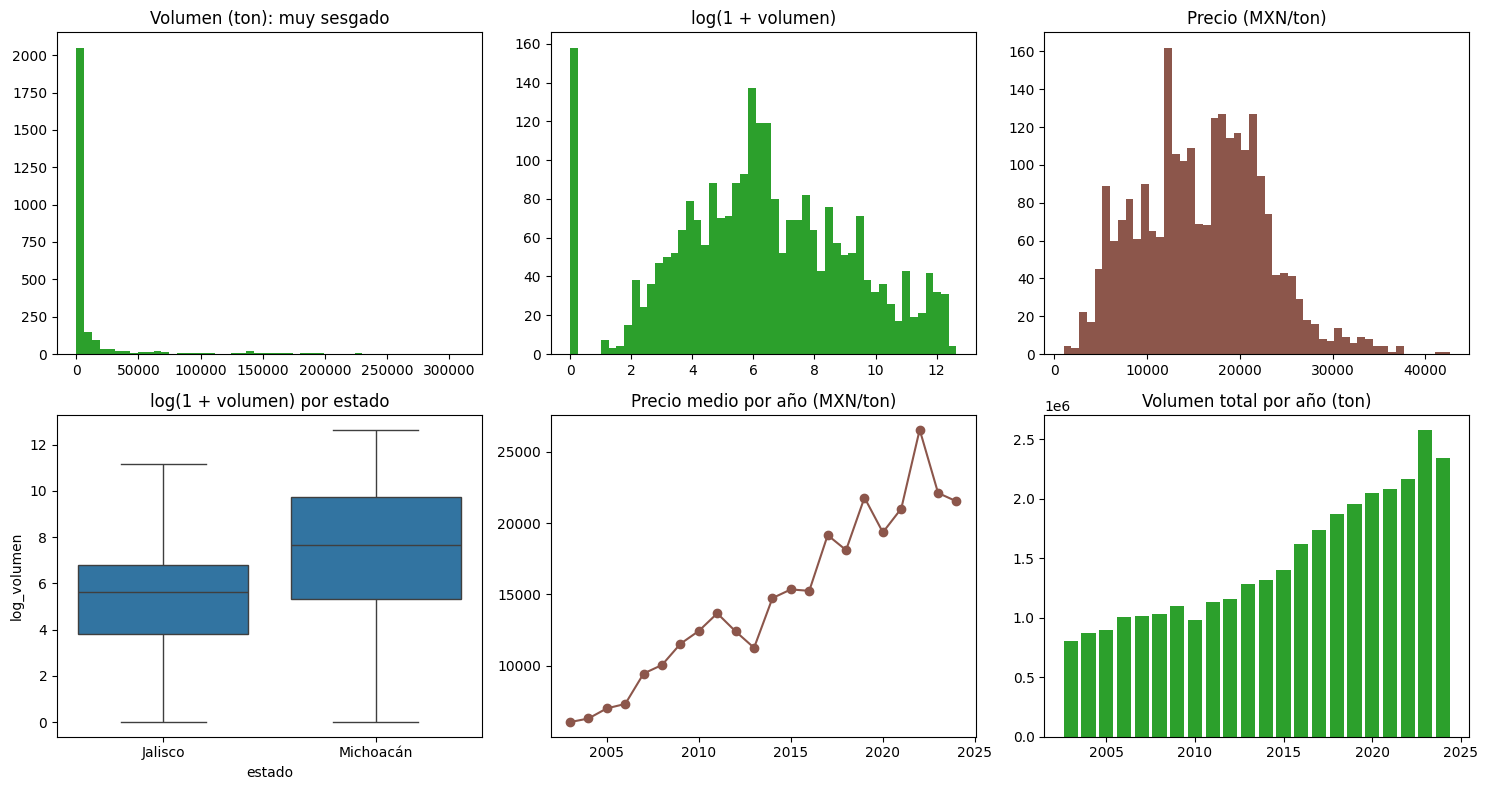


Filas cuyo año previo del mismo municipio NO es t-1: 13 de 2594


In [20]:
print('Panel municipio × año:', panel.shape)
print(f'Años: {int(panel.anio.min())}–{int(panel.anio.max())} | municipios: {panel.clave_mun.nunique()} | estados: {panel.estado.nunique()}')

NUM = [c for c in panel.columns if pd.api.types.is_numeric_dtype(panel[c]) and c not in ('anio', 'periodo_obj')]
desc = panel[NUM].describe().T
desc['faltantes_%'] = panel[NUM].isna().mean() * 100
desc['cv'] = desc['std'] / desc['mean']
desc['asimetria'] = panel[NUM].skew()
display(desc.round(2))
desc.round(3).to_csv(SALIDAS2 / 'estadistica_descriptiva.csv')

por_estado = (panel.groupby('estado')
              .agg(municipios=('clave_mun', 'nunique'), filas=('clave_mun', 'size'),
                   volumen_total=('volumen', 'sum'), precio_medio=('precio_kg', 'mean'), precio_desv=('precio_kg', 'std')).round(1))
por_anio = (panel.groupby('anio')
            .agg(municipios=('clave_mun', 'nunique'), volumen_total=('volumen', 'sum'),
                 precio_medio=('precio_kg', 'mean'), sequia_media=('sequia_sev_media_anual', 'mean')).round(1))
display(por_estado)
display(por_anio)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0, 0].hist(panel['volumen'].dropna(), bins=50, color='tab:green');                ax[0, 0].set_title('Volumen (ton): muy sesgado')
ax[0, 1].hist(np.log1p(panel['volumen'].dropna()), bins=50, color='tab:green');      ax[0, 1].set_title('log(1 + volumen)')
ax[0, 2].hist(panel['precio_kg'].dropna(), bins=50, color='tab:brown');              ax[0, 2].set_title('Precio (MXN/ton)')
sns.boxplot(data=panel.assign(log_volumen=np.log1p(panel['volumen'])), x='estado', y='log_volumen', ax=ax[1, 0])
ax[1, 0].set_title('log(1 + volumen) por estado')
ax[1, 1].plot(por_anio.index, por_anio['precio_medio'], marker='o', color='tab:brown'); ax[1, 1].set_title('Precio medio por año (MXN/ton)')
ax[1, 2].bar(por_anio.index, por_anio['volumen_total'], color='tab:green');          ax[1, 2].set_title('Volumen total por año (ton)')
plt.tight_layout(); plt.show()

# Chequeo de huecos: ¿algún municipio salta años? (si salta, "la fila anterior" no es "el año anterior")
sal = panel.sort_values(['clave_mun', 'anio']).groupby('clave_mun')['anio'].diff()
print(f"\nFilas cuyo año previo del mismo municipio NO es t-1: {int((sal > 1).sum())} de {len(panel)}")

## 14. ¿Cómo afectan el clima, la sequía, los ciclones y los desastres?

En las secciones 11 y 13 el clima casi no aparece como predictor (importancia ≈ 0.1% en oferta). Antes de concluir que "no importa", conviene mirar el fenómeno de otras formas, porque un modelo anual con valores brutos puede esconder efectos que aparecen en **cambios**, **rezagos** o **meses concretos**.

**Cómo se mide el efecto**
1. **Cambio interanual pareado.** Para cada año se compara contra el anterior usando **solo los municipios que tienen producción en ambos años**. Sin esto, la producción "sube" cuando se suman municipios nuevos al panel (el panel pasa de 78 municipios en 2003 a 146 en 2024).
2. **Años de evento contra años sin evento.** Un año es de *sequía fuerte* si el índice de su estado está en el 25% más alto de su propia historia; de *ciclones* igual con los meses con ciclón; de *desastre* si hubo al menos un evento EM-DAT. Se compara el cambio de volumen y de precio **en ese año** y **en el siguiente** (un árbol afectado puede producir menos al año siguiente).
3. **Qué mes importa.** Correlación entre la severidad de la sequía de cada mes (del mismo año y del año anterior) y el cambio de producción del municipio.
4. **Comparación dentro del mismo estado y año.** Se resta a cada municipio la mediana de su estado en ese año. Así se quitan los choques comunes (precio nacional, mercado) y solo queda la diferencia entre municipios más o menos castigados por la sequía.

**Cómo leer los resultados.** Con 2 estados y ~21 años hay pocos eventos: los valores p a nivel estado-año son orientativos. A nivel municipio hay miles de observaciones, pero un mismo evento afecta a todos los municipios de un estado a la vez, así que **no son independientes** y no se reportan valores p allí, solo la magnitud de la correlación. Como regla práctica (convención, no ley), |ρ| < 0.1 se considera despreciable.

Observaciones municipio-año con año previo: 2,262 de 2,594


,estado,anio,n_mun,d_vol_pct,d_precio_pct,sequia_media,meses_severos,ciclon_meses,desastres,clima_precip_lluvias_anom_pct,clima_temp_media_anom
0,Jalisco,2004,35,-12.5,-2.4,0.1,0.0,1,0.0,NaN,NaN
1,Jalisco,2005,35,23.5,23.0,0.6,0.0,3,0.0,NaN,NaN
2,Jalisco,2006,39,9.7,10.8,1.6,2.0,4,0.0,NaN,NaN
3,Jalisco,2007,38,59.7,28.6,1.7,2.2,2,1.0,NaN,NaN
4,Jalisco,2008,39,4.5,13.8,1.7,1.4,4,0.0,NaN,NaN
5,Jalisco,2009,48,32.0,11.7,1.9,1.4,3,0.0,NaN,NaN
6,Jalisco,2010,50,88.7,-0.7,0.0,0.0,2,0.0,NaN,NaN
7,Jalisco,2011,51,25.5,-18.1,1.8,3.2,5,2.0,NaN,NaN
8,Jalisco,2012,53,8.2,19.3,0.4,0.2,3,0.0,NaN,NaN
9,Jalisco,2013,53,98.5,-20.3,0.3,0.1,4,1.0,NaN,NaN


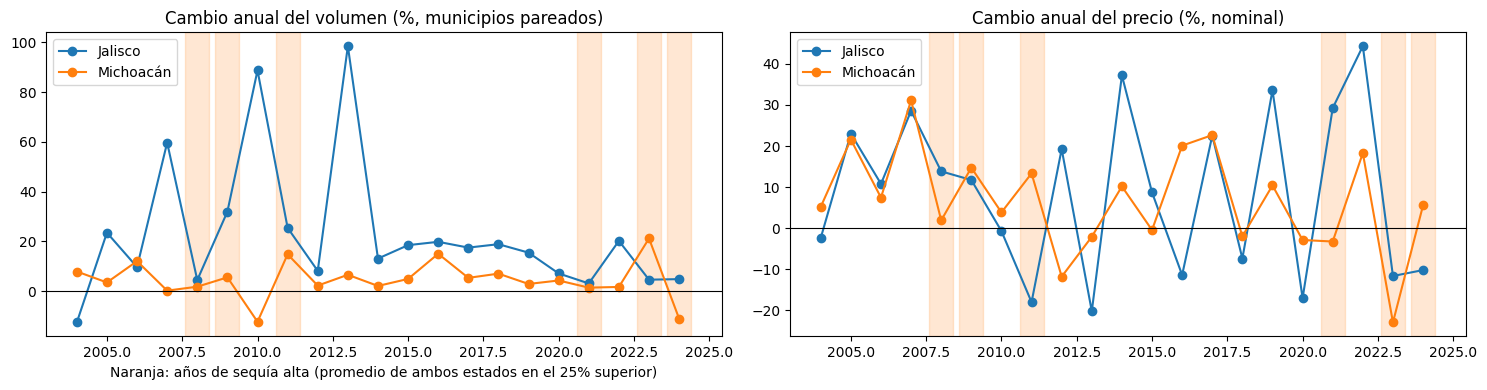

In [21]:
# ---------- 14.1 Cambios interanuales pareados (municipio y estado) ----------
def cambios_pareados(df):
    d = df[df['volumen'] > 0][['clave_mun', 'clave_estado', 'anio', 'volumen', 'valor_miles',
                               'sequia_sev_media_anual', 'sequia_meses_severos']].copy()
    prev = d[['clave_mun', 'anio', 'volumen', 'valor_miles']].copy()
    prev['anio'] += 1
    prev = prev.rename(columns={'volumen': 'vol_prev', 'valor_miles': 'val_prev'})
    m = d.merge(prev, on=['clave_mun', 'anio'], how='inner')
    m['d_logvol'] = np.log(m['volumen'] / m['vol_prev'])
    m['precio'] = m['valor_miles'] / m['volumen']
    m['precio_prev'] = m['val_prev'] / m['vol_prev']
    m['d_logprecio'] = np.log(m['precio'] / m['precio_prev']).replace([np.inf, -np.inf], np.nan)
    return m


mun = cambios_pareados(panel)                                   # una fila por municipio-año con año previo
print(f'Observaciones municipio-año con año previo: {len(mun):,} de {len(panel):,}')

est = (mun.groupby(['clave_estado', 'anio'])
          .agg(n_mun=('clave_mun', 'nunique'), vol=('volumen', 'sum'), vol_prev=('vol_prev', 'sum'),
               val=('valor_miles', 'sum'), val_prev=('val_prev', 'sum'),
               sequia_media=('sequia_sev_media_anual', 'mean'), meses_severos=('sequia_meses_severos', 'mean'))
          .reset_index())
est['d_vol_pct'] = (est['vol'] / est['vol_prev'] - 1) * 100
est['d_precio_pct'] = ((est['val'] / est['vol']) / (est['val_prev'] / est['vol_prev']) - 1) * 100
expo = panel.groupby(['clave_estado', 'anio']).agg(ciclon_meses=('ciclon_meses', 'first'),
                                                    desastres=('desastre_eventos_anual', 'first')).reset_index()
est = est.merge(expo, on=['clave_estado', 'anio'], how='left')
if df_clima_jm_anual is not None:
    est = est.merge(df_clima_jm_anual[['clave_estado', 'anio', 'clima_precip_lluvias_anom_pct', 'clima_temp_media_anom']],
                    on=['clave_estado', 'anio'], how='left')
# cambio del AÑO SIGUIENTE (t+1 contra t): ¿el golpe se nota con un año de retraso?
sig = est[['clave_estado', 'anio', 'd_vol_pct', 'd_precio_pct']].copy()
sig['anio'] -= 1
est = est.merge(sig.rename(columns={'d_vol_pct': 'd_vol_pct_sig', 'd_precio_pct': 'd_precio_pct_sig'}),
                on=['clave_estado', 'anio'], how='left')
est['estado'] = est['clave_estado'].map(ENTIDADES)

cols_ver = ['estado', 'anio', 'n_mun', 'd_vol_pct', 'd_precio_pct', 'sequia_media', 'meses_severos', 'ciclon_meses', 'desastres']
if df_clima_jm_anual is not None:
    cols_ver += ['clima_precip_lluvias_anom_pct', 'clima_temp_media_anom']
display(est.sort_values(['estado', 'anio'])[cols_ver].round(1))
est.round(3).to_csv(SALIDAS2 / 'cambios_estado_anio.csv', index=False, encoding='utf-8-sig')

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharex=True)
for cve, g in est.groupby('clave_estado'):
    axes[0].plot(g['anio'], g['d_vol_pct'], marker='o', label=ENTIDADES[cve])
    axes[1].plot(g['anio'], g['d_precio_pct'], marker='o', label=ENTIDADES[cve])
for ax, t in zip(axes, ['Cambio anual del volumen (%, municipios pareados)', 'Cambio anual del precio (%, nominal)']):
    ax.axhline(0, color='k', lw=0.8); ax.set_title(t); ax.legend()
    for a_, sv in est.groupby('anio')['sequia_media'].mean().items():
        if sv >= est['sequia_media'].quantile(0.75):
            ax.axvspan(a_ - 0.4, a_ + 0.4, color='tab:orange', alpha=0.18)
axes[0].set_xlabel('Naranja: años de sequía alta (promedio de ambos estados en el 25% superior)')
plt.tight_layout(); plt.show()

In [22]:
# ---------- 14.2 Años de evento contra años sin evento (a nivel estado-año) ----------
def marca_evento(df, col, p=0.75, minimo=None):
    umbral = df.groupby('clave_estado')[col].transform(lambda s: s.quantile(p))
    f = df[col] >= umbral
    return f & (df[col] >= minimo) if minimo is not None else f


est['ev_sequia'] = marca_evento(est, 'sequia_media')
est['ev_ciclon'] = marca_evento(est, 'ciclon_meses', minimo=1)
est['ev_desastre'] = est['desastres'].fillna(0) >= 1

EFECTOS = [('d_vol_pct', 'volumen, mismo año'), ('d_vol_pct_sig', 'volumen, año siguiente'),
           ('d_precio_pct', 'precio, mismo año'), ('d_precio_pct_sig', 'precio, año siguiente')]


def comparar_eventos(df, flag, nombre):
    filas = []
    for col, etiqueta in EFECTOS:
        a, b = df.loc[df[flag], col].dropna(), df.loc[~df[flag], col].dropna()
        p = stats.mannwhitneyu(a, b).pvalue if len(a) >= 3 and len(b) >= 3 else np.nan
        filas.append({'evento': nombre, 'efecto medido': etiqueta, 'n con evento': len(a), 'n sin evento': len(b),
                      'mediana con evento (%)': a.median(), 'mediana sin evento (%)': b.median(),
                      'diferencia (pts)': a.median() - b.median(), 'p (Mann-Whitney)': p})
    return pd.DataFrame(filas)


tabla_eventos = pd.concat([comparar_eventos(est, 'ev_sequia', 'Sequía fuerte'),
                           comparar_eventos(est, 'ev_ciclon', 'Año con ciclones'),
                           comparar_eventos(est, 'ev_desastre', 'Año con desastre EM-DAT')], ignore_index=True)
display(tabla_eventos.round(3))
tabla_eventos.round(3).to_csv(SALIDAS2 / 'eventos_vs_normales.csv', index=False, encoding='utf-8-sig')

# Los eventos uno por uno, con su efecto (esto responde "en el año X hubo sequía y el volumen cambió Y%")
ev = est[est['ev_sequia']][['estado', 'anio', 'sequia_media', 'meses_severos', 'd_vol_pct', 'd_vol_pct_sig', 'd_precio_pct', 'd_precio_pct_sig']]
print('\nAños de sequía fuerte, uno por uno (cambios en %):')
display(ev.sort_values(['estado', 'anio']).round(1))
ev.round(2).to_csv(SALIDAS2 / 'sequias_fuertes_detalle.csv', index=False, encoding='utf-8-sig')

,evento,efecto medido,n con evento,n sin evento,mediana con evento (%),mediana sin evento (%),diferencia (pts),p (Mann-Whitney)
0,Sequía fuerte,"volumen, mismo año",12,30,7.660,7.126,0.534,0.770
1,Sequía fuerte,"volumen, año siguiente",11,29,4.884,9.725,-4.841,0.413
2,Sequía fuerte,"precio, mismo año",12,30,8.160,8.058,0.101,0.427
3,Sequía fuerte,"precio, año siguiente",11,29,11.718,8.695,3.022,0.880
4,Año con ciclones,"volumen, mismo año",23,19,6.629,7.945,-1.316,0.820
5,Año con ciclones,"volumen, año siguiente",23,17,8.196,7.087,1.109,0.805
6,Año con ciclones,"precio, mismo año",23,19,1.874,11.718,-9.844,0.061
7,Año con ciclones,"precio, año siguiente",23,17,10.387,-0.744,11.131,0.155
8,Año con desastre EM-DAT,"volumen, mismo año",16,26,13.991,5.492,8.500,0.344
9,Año con desastre EM-DAT,"volumen, año siguiente",15,25,4.658,9.725,-5.068,0.209



Años de sequía fuerte, uno por uno (cambios en %):


,estado,anio,sequia_media,meses_severos,d_vol_pct,d_vol_pct_sig,d_precio_pct,d_precio_pct_sig
2,Jalisco,2006,1.6,2.0,9.7,59.7,10.8,28.6
3,Jalisco,2007,1.7,2.2,59.7,4.5,28.6,13.8
4,Jalisco,2008,1.7,1.4,4.5,32.0,13.8,11.7
5,Jalisco,2009,1.9,1.4,32.0,88.7,11.7,-0.7
7,Jalisco,2011,1.8,3.2,25.5,8.2,-18.1,19.3
19,Jalisco,2023,2.8,5.8,4.7,4.9,-11.7,-10.2
25,Michoacán,2008,2.4,3.0,1.8,5.6,1.9,14.7
26,Michoacán,2009,2.5,4.1,5.6,-12.2,14.7,3.8
28,Michoacán,2011,1.7,1.7,14.8,2.3,13.3,-11.9
38,Michoacán,2021,1.9,4.5,1.5,1.7,-3.3,18.3


Cambio mediano (%) según el cuartil de severidad de sequía del municipio-año:


,municipio_anio,sequia_media,vol_mismo_anio_mediana,vol_anio_sig_mediana,precio_mismo_anio_mediana,precio_anio_sig_mediana
grupo_sequia,,,,,,
Q1 sequía menor,566,0.16,5.02,7.16,0.13,3.65
Q2,565,0.71,4.99,3.35,4.99,6.70
Q3,565,1.28,2.84,2.81,13.16,-1.46
Q4 sequía mayor,566,2.39,1.94,1.51,-1.00,3.09


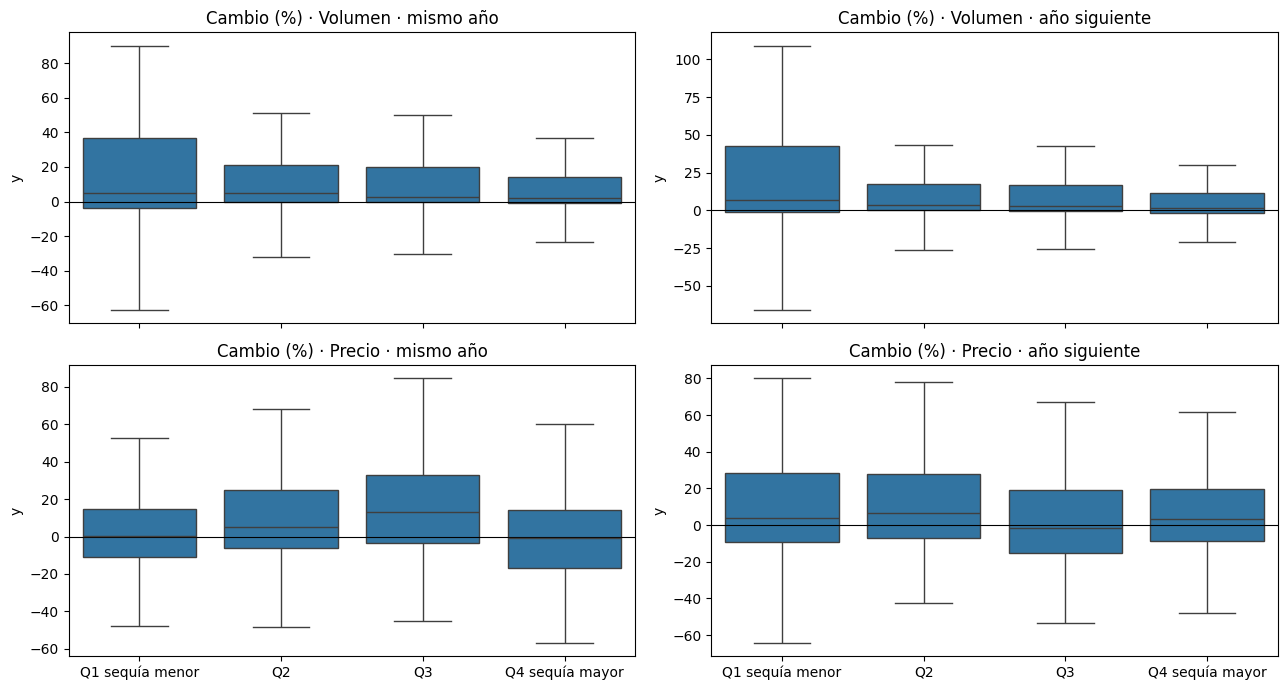

In [23]:
# ---------- 14.3 ¿Hay relación no lineal? Municipios agrupados por severidad de sequía ----------
nx = mun[['clave_mun', 'anio', 'd_logvol', 'd_logprecio']].copy()
nx['anio'] -= 1
mun2 = mun.merge(nx.rename(columns={'d_logvol': 'd_logvol_sig', 'd_logprecio': 'd_logprecio_sig'}), on=['clave_mun', 'anio'], how='left')
mun2['grupo_sequia'] = pd.qcut(mun2['sequia_sev_media_anual'].rank(method='first'), 4,
                               labels=['Q1 sequía menor', 'Q2', 'Q3', 'Q4 sequía mayor'])
pct = lambda s: (np.exp(s) - 1) * 100
resumen_q = (mun2.groupby('grupo_sequia')
             .agg(municipio_anio=('clave_mun', 'size'),
                  sequia_media=('sequia_sev_media_anual', 'mean'),
                  vol_mismo_anio_mediana=('d_logvol', lambda s: pct(s.median())),
                  vol_anio_sig_mediana=('d_logvol_sig', lambda s: pct(s.median())),
                  precio_mismo_anio_mediana=('d_logprecio', lambda s: pct(s.median())),
                  precio_anio_sig_mediana=('d_logprecio_sig', lambda s: pct(s.median()))).round(2))
print('Cambio mediano (%) según el cuartil de severidad de sequía del municipio-año:')
display(resumen_q)

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, (col, t) in zip(axes.flat, [('d_logvol', 'Volumen · mismo año'), ('d_logvol_sig', 'Volumen · año siguiente'),
                                   ('d_logprecio', 'Precio · mismo año'), ('d_logprecio_sig', 'Precio · año siguiente')]):
    sns.boxplot(data=mun2.assign(y=pct(mun2[col])), x='grupo_sequia', y='y', ax=ax, showfliers=False)
    ax.axhline(0, color='k', lw=0.8); ax.set_title(f'Cambio (%) · {t}'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

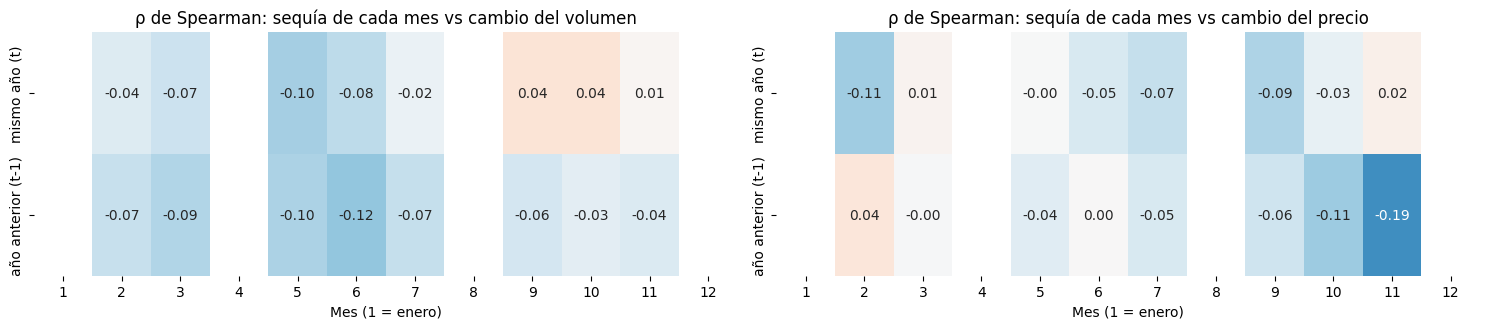

Rojo: más sequía en ese mes se asocia con MÁS aumento; azul: con MENOS aumento. Con |ρ| < 0.1 la relación es despreciable.
ρ de Spearman con el cambio del municipio (sin valores p: las observaciones comparten el mismo evento):


,volumen (t),volumen (t+1),precio (t),precio (t+1)
variable,,,,
Severidad media de sequía del año,-0.058,-0.117,-0.034,-0.066
Meses con sequía severa (D2+),-0.113,-0.118,-0.104,-0.005
Meses con ciclón cerca de la costa,0.088,0.048,-0.048,0.087
Eventos de desastre EM-DAT,-0.014,0.042,0.109,0.108
Sequía del municipio vs su estado ese año,0.020,0.037,-0.059,0.020


In [24]:
# ---------- 14.4 ¿Qué mes de sequía importa? (mismo año y año anterior) ----------
def mapa_mes_sequia(sq_m, base, objetivo):
    '''Correlación de Spearman entre la severidad de sequía de cada mes (año t o t-1) y el cambio de t.'''
    w = sq_m.pivot_table(index=['clave_mun', 'anio'], columns='mes', values='sequia_sev_max').reset_index()
    filas = {}
    for lag, nombre in [(0, 'mismo año (t)'), (1, 'año anterior (t-1)')]:
        wl = w.copy()
        wl['anio'] = wl['anio'] + lag                        # la sequía del año (t - lag) se asigna al año t
        j = base[['clave_mun', 'anio', objetivo]].merge(wl, on=['clave_mun', 'anio']).dropna(subset=[objetivo])
        filas[nombre] = [stats.spearmanr(j[m], j[objetivo], nan_policy='omit')[0] if m in j.columns else np.nan
                         for m in range(1, 13)]
    return pd.DataFrame(filas, index=range(1, 13)).T


fig, axes = plt.subplots(1, 2, figsize=(15, 3.4))
for ax, (col, t) in zip(axes, [('d_logvol', 'cambio del volumen'), ('d_logprecio', 'cambio del precio')]):
    mm = mapa_mes_sequia(df_sequia_mensual, mun, col)
    sns.heatmap(mm, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-0.3, vmax=0.3, ax=ax, cbar=False)
    ax.set_title(f'ρ de Spearman: sequía de cada mes vs {t}'); ax.set_xlabel('Mes (1 = enero)')
plt.tight_layout(); plt.show()
print('Rojo: más sequía en ese mes se asocia con MÁS aumento; azul: con MENOS aumento. Con |ρ| < 0.1 la relación es despreciable.')

# ---------- 14.5 Resumen de relaciones (municipio-año) ----------
# a) relación cruda  b) relativa al estado-año (se quita el choque común: precio nacional, mercado, etc.)
mun2['ky'] = mun2['clave_estado'] + '_' + mun2['anio'].astype(str)
for col in ['d_logvol', 'd_logvol_sig', 'd_logprecio', 'd_logprecio_sig']:
    mun2[col + '_rel'] = mun2[col] - mun2.groupby('ky')[col].transform('median')
mun2['sequia_rel'] = mun2['sequia_sev_media_anual'] - mun2.groupby('ky')['sequia_sev_media_anual'].transform('mean')
mun2 = mun2.merge(expo.rename(columns={'desastres': 'desastres_est'}), on=['clave_estado', 'anio'], how='left', suffixes=('', '_e'))

filas = []
for var, etiqueta in [('sequia_sev_media_anual', 'Severidad media de sequía del año'),
                      ('sequia_meses_severos', 'Meses con sequía severa (D2+)'),
                      ('ciclon_meses', 'Meses con ciclón cerca de la costa'),
                      ('desastres_est', 'Eventos de desastre EM-DAT'),
                      ('sequia_rel', 'Sequía del municipio vs su estado ese año')]:
    fila = {'variable': etiqueta}
    for obj in ['d_logvol', 'd_logvol_sig', 'd_logprecio', 'd_logprecio_sig']:
        oc = obj + '_rel' if var == 'sequia_rel' else obj
        d_ = mun2[[var, oc]].dropna()
        fila[{'d_logvol': 'volumen (t)', 'd_logvol_sig': 'volumen (t+1)', 'd_logprecio': 'precio (t)', 'd_logprecio_sig': 'precio (t+1)'}[obj]] = \
            round(stats.spearmanr(d_[var], d_[oc])[0], 3) if len(d_) > 30 and d_[var].nunique() > 1 else np.nan
    filas.append(fila)
rel = pd.DataFrame(filas).set_index('variable')
print('ρ de Spearman con el cambio del municipio (sin valores p: las observaciones comparten el mismo evento):')
display(rel)
rel.to_csv(SALIDAS2 / 'correlaciones_cambios.csv', encoding='utf-8-sig')

### 14.6 Variables nuevas de sequía para el modelo (historia larga)

Con la sequía mensual se construyen variables que la entrega anterior no tenía. Las ventanas se fijan **de antemano** (no se eligen mirando qué mes salió mejor, para no hacer trampa con la prueba): temporada seca (enero–mayo), temporada de lluvias (junio–septiembre), el máximo del año, la sequía del **año anterior** y el cambio frente a ese año.

El rezago se calcula con el **año calendario** anterior, no con "la fila anterior".

In [25]:
sq = df_sequia_mensual.copy()
sq['sev'] = sq['sequia_sev_max']
sec_ = (sq.assign(ventana=np.where(sq['mes'].between(1, 5), 'sequia_secas', np.where(sq['mes'].between(6, 9), 'sequia_lluvias', 'otros')))
          .query("ventana != 'otros'")
          .groupby(['clave_mun', 'anio', 'ventana'])['sev'].mean().unstack('ventana').reset_index())
mx_ = sq.groupby(['clave_mun', 'anio'], as_index=False)['sev'].max().rename(columns={'sev': 'sequia_max'})
feat_sq = sec_.merge(mx_, on=['clave_mun', 'anio'], how='outer')

panel = panel.drop(columns=[c for c in CLIMA_ESTACIONAL if c in panel.columns])
panel = panel.merge(feat_sq, on=['clave_mun', 'anio'], how='left')
prev_sq = panel[['clave_mun', 'anio', 'sequia_sev_media_anual']].copy()
prev_sq['anio'] += 1
panel = panel.merge(prev_sq.rename(columns={'sequia_sev_media_anual': 'sequia_lag1'}), on=['clave_mun', 'anio'], how='left')
panel['sequia_cambio'] = panel['sequia_sev_media_anual'] - panel['sequia_lag1']
panel = panel.sort_values(['clave_mun', 'anio']).reset_index(drop=True)
print('Variables nuevas de sequía:', CLIMA_ESTACIONAL)
display(panel[CLIMA_ESTACIONAL].describe().T.round(2))

Variables nuevas de sequía: ['sequia_secas', 'sequia_lluvias', 'sequia_max', 'sequia_lag1', 'sequia_cambio']


,count,mean,std,min,25%,50%,75%,max
sequia_secas,2594.0,1.22,1.13,0.00,0.00,1.00,2.00,4.00
sequia_lluvias,2594.0,1.30,1.08,0.00,0.33,1.00,2.00,4.00
sequia_max,2594.0,2.06,1.25,0.00,1.00,2.00,3.00,5.00
sequia_lag1,2423.0,1.04,0.87,0.00,0.38,0.88,1.50,3.75
sequia_cambio,2423.0,0.08,1.02,-3.12,-0.38,0.12,0.56,3.25


## 15. Partición de los datos: 60/40 contra 70/30

La partición es **temporal**: el entrenamiento usa los años más antiguos y la prueba los más recientes. Una partición aleatoria dejaría en el entrenamiento a otros municipios del mismo año que luego se "predice", y la prueba no mediría un pronóstico real. El corte se coloca donde el acumulado de filas queda más cerca de la fracción pedida.

Los datos que se usan son históricos (2003–2024) y ya no se van a ampliar, así que la partición se decide con la evidencia del propio histórico: se comparan **60/40** y **70/30**. Cada corte tiene una prueba distinta, y por eso en la sección 17 los dos modelos también se evalúan sobre la **misma ventana de años** para que la comparación sea justa.

,Split,Entrenamiento,Filas entren.,% real entren.,Prueba,Filas prueba
0,60/40,2004–2017,1346,58.0,2018–2024,975
1,70/30,2004–2019,1616,69.6,2020–2024,705


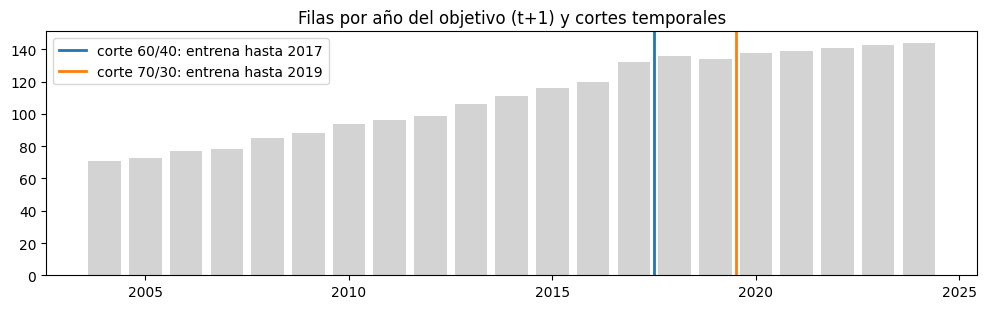

In [26]:
def split_temporal(df, frac, col='periodo_obj'):
    '''Entrenamiento = años más antiguos, prueba = años más recientes. Devuelve (train, test, año_de_corte).'''
    cnt = df.groupby(col).size().sort_index()
    if len(cnt) < 2:
        raise ValueError('Se necesitan al menos 2 periodos para separar entrenamiento y prueba')
    acum = cnt.cumsum() / cnt.sum()
    corte = (acum.iloc[:-1] - frac).abs().idxmin()            # deja al menos un año para prueba
    return df[df[col] <= corte], df[df[col] > corte], int(corte)


con_obj = panel.dropna(subset=['y_volumen_sig', 'y_precio_sig'])
filas = []
for f in SPLITS:
    tr_, te_, c_ = split_temporal(con_obj, f)
    filas.append({'Split': f'{int(f * 100)}/{int(round((1 - f) * 100))}', 'Entrenamiento': f'{int(tr_.periodo_obj.min())}–{c_}',
                  'Filas entren.': len(tr_), '% real entren.': round(len(tr_) / len(con_obj) * 100, 1),
                  'Prueba': f'{c_ + 1}–{int(te_.periodo_obj.max())}', 'Filas prueba': len(te_)})
display(pd.DataFrame(filas))

fig, ax = plt.subplots(figsize=(10, 3.2))
cnt = con_obj.groupby('periodo_obj').size()
ax.bar(cnt.index, cnt.values, color='lightgray')
for f, col in zip(SPLITS, ['tab:blue', 'tab:orange']):
    _, _, c_ = split_temporal(con_obj, f)
    ax.axvline(c_ + 0.5, color=col, lw=2, label=f'corte {int(f * 100)}/{int(round((1 - f) * 100))}: entrena hasta {c_}')
ax.set_title('Filas por año del objetivo (t+1) y cortes temporales'); ax.legend(); plt.tight_layout(); plt.show()

## 16. Universo apto de filas y columnas con ANOVA

**Filas.** Una fila es apta si cumple todas las reglas; cada exclusión queda anotada en `motivo_exclusion`.

**Columnas.** Cada columna candidata se convierte en grupos (sus valores si tiene 4 o menos, terciles si tiene más) y se compara el objetivo (en log) entre grupos.
- **H₀:** la media del objetivo es igual en todos los grupos. **H₁:** al menos un grupo difiere.
- **η²:** proporción de la variación del objetivo que explican los grupos (0.01 pequeño, 0.06 mediano, 0.14 grande; convención de Cohen).
- **Supuestos:** si Levene rechaza igualdad de varianzas, la decisión usa Welch.
- **Bonferroni:** el valor p se multiplica por el número de pruebas.
- **Se conserva** una columna si p ajustado < 0.05 **y** η² ≥ 0.01. De dos columnas con |r| > 0.9 se queda la de mayor F.

El ANOVA se calcula **solo con entrenamiento**, y **por separado para cada partición** (60/40 y 70/30), para que la selección de columnas no use información de la prueba.

*Limitación:* un municipio aparece en varios años, así que las observaciones no son independientes y los valores p salen optimistas. Por eso se exige también un tamaño de efecto mínimo.

In [27]:
CAND = BASE + CLIMA_ANUAL + CLIMA_ESTACIONAL            # columnas candidatas del ANOVA (historia larga)

u = panel.copy()
u['registro_apto'] = True
u['motivo_exclusion'] = ''


def marcar(mask, motivo):
    u.loc[mask, 'registro_apto'] = False
    u.loc[mask, 'motivo_exclusion'] += motivo + '; '


marcar(u.duplicated(['clave_mun', 'anio'], keep='first'), 'Duplicado municipio-año')
marcar(~(u['volumen'] > 0), 'Volumen nulo o ≤ 0')
marcar(~(u['cosechada_ha'] > 0), 'Sin superficie cosechada')
marcar(~(u['precio_kg'] > 0), 'Precio nulo o ≤ 0')
marcar(~((u['y_volumen_sig'] > 0) & (u['y_precio_sig'] > 0)), 'Sin objetivo válido en t+1')
marcar(u[CAND].isna().any(axis=1), 'Falta una variable candidata')

u['ly_vol'] = np.log1p(u['y_volumen_sig'])
u['ly_pre'] = np.log(u['y_precio_sig'].where(u['y_precio_sig'] > 0))
anios = sorted(u['anio'].unique())
c1, c2 = anios[len(anios) // 3 - 1], anios[2 * len(anios) // 3 - 1]
u['periodo'] = pd.cut(u['anio'], [-np.inf, c1, c2, np.inf],
                      labels=[f'≤{int(c1)}', f'{int(c1) + 1}–{int(c2)}', f'≥{int(c2) + 1}']).astype(str)

resumen_excl = (u.loc[~u['registro_apto'], 'motivo_exclusion'].str.strip('; ').str.split('; ')
                .explode().value_counts().rename('filas').to_frame())
resumen_excl['% del panel'] = (resumen_excl['filas'] / len(u) * 100).round(1)
print(f"Filas del panel: {len(u):,} | aptas: {int(u.registro_apto.sum()):,} | excluidas: {int((~u.registro_apto).sum()):,}")
display(resumen_excl)

universo = u[u['registro_apto']].copy()
universo.to_csv(SALIDAS2 / 'universo_apto.csv', index=False, encoding='utf-8-sig')
u[~u['registro_apto']].to_csv(SALIDAS2 / 'registros_excluidos.csv', index=False, encoding='utf-8-sig')
print('Una fila con valor atípico no se elimina por serlo: los atípicos reales (municipios muy grandes) son parte del negocio.')

Filas del panel: 2,594 | aptas: 2,097 | excluidas: 497


,filas,% del panel
motivo_exclusion,,
Falta una variable candidata,332,12.8
Sin objetivo válido en t+1,273,10.5
Volumen nulo o ≤ 0,156,6.0
Precio nulo o ≤ 0,156,6.0
Sin superficie cosechada,156,6.0


Una fila con valor atípico no se elimina por serlo: los atípicos reales (municipios muy grandes) son parte del negocio.


In [28]:
def a_grupos(s):
    '''Convierte una variable numérica en grupos: sus valores si tiene ≤ 4, o terciles si tiene más.'''
    s = pd.to_numeric(s, errors='coerce')
    if s.nunique() <= 4:
        g = s.astype(str)
    else:
        try:
            g = pd.qcut(s, 3, duplicates='drop').astype(str)
        except ValueError:
            g = pd.cut(s, 2).astype(str)
    return g.where(s.notna())


def anova_col(y, g):
    '''ANOVA de una vía de y entre los grupos g, con Levene y Welch. Devuelve un diccionario o None.'''
    d = pd.DataFrame({'y': y, 'g': g}).dropna()
    grupos = [x['y'].values for _, x in d.groupby('g') if len(x) >= 2]
    if len(grupos) < 2:
        return None
    gm = d['y'].mean()
    ss_total = ((d['y'] - gm) ** 2).sum()
    if ss_total == 0:
        return None
    F, p = stats.f_oneway(*grupos)
    ss_entre = sum(len(x) * (x.mean() - gm) ** 2 for x in grupos)
    p_levene = stats.levene(*grupos, center='median').pvalue
    p_welch = float(anova_oneway(grupos, use_var='unequal', welch_correction=True).pvalue)
    return {'k_grupos': len(grupos), 'n': len(d), 'F': F, 'eta2': ss_entre / ss_total, 'p_levene': p_levene,
            'p_decision': p_welch if p_levene < ALPHA else p}


def prep_X(df, feats):
    X = df[feats].astype(float).copy()
    for c in LOG_FEATS:
        if c in X.columns:
            X[c] = np.log1p(X[c])
    return X


def seleccionar_columnas(train, candidatas=None):
    '''ANOVA por columna (solo entrenamiento) + Bonferroni + η² + filtro de redundancia.
    Devuelve (columnas elegidas por objetivo, tabla ANOVA completa, columnas descartadas por redundancia).'''
    candidatas = candidatas or CAND
    tablas, elegidas, redundantes = [], {}, {}
    for obj, ycol in YLOG.items():
        res = []
        for c in FACTORES + candidatas:
            g = train[c] if c in FACTORES else a_grupos(train[c])
            r = anova_col(train[ycol], g)
            if r:
                r.update(objetivo=obj, columna=c, tipo='factor' if c in FACTORES else 'candidata')
                res.append(r)
        m = len(res)
        for r in res:
            r['p_ajustada'] = min(1.0, r['p_decision'] * m)
            r['conserva'] = bool(r['p_ajustada'] < ALPHA and r['eta2'] >= ETA2_MIN)
        t = pd.DataFrame(res)
        tablas.append(t)
        pasan = t[(t['tipo'] == 'candidata') & t['conserva']].sort_values('F', ascending=False)['columna'].tolist()
        corr = prep_X(train, pasan).corr().abs() if pasan else None
        finales, descartadas = [], []
        for c in pasan:
            previa = next((k for k in finales if corr.loc[c, k] > R_MAX), None)
            if previa is None:
                finales.append(c)
            else:
                descartadas.append((c, previa, round(float(corr.loc[c, previa]), 3)))
        if not finales:
            print(f'AVISO: ANOVA no conservó ninguna columna para {obj}; se usa la base BASE.')
            finales = list(BASE)
        elegidas[obj], redundantes[obj] = finales, descartadas
    return elegidas, pd.concat(tablas, ignore_index=True), redundantes


SEL, ANOVA_TAB, REDUND = {}, {}, {}
for f in SPLITS:
    tr_, te_, c_ = split_temporal(universo, f)
    SEL[f], ANOVA_TAB[f], REDUND[f] = seleccionar_columnas(tr_)
    print(f'\n=== ANOVA con partición {int(f * 100)}/{int(round((1 - f) * 100))} (entrenamiento hasta {c_}, {len(tr_)} filas) ===')
    cols_ver = ['objetivo', 'columna', 'tipo', 'k_grupos', 'n', 'F', 'eta2', 'p_levene', 'p_decision', 'p_ajustada', 'conserva']
    display(ANOVA_TAB[f][cols_ver].round(4))
    ANOVA_TAB[f].to_csv(SALIDAS2 / f'anova_columnas_{int(f * 100)}.csv', index=False, encoding='utf-8-sig')
    for obj in OBJETIVOS:
        print(f'{obj}\n   conservadas: {SEL[f][obj]}\n   descartadas por redundancia (columna, se queda con, |r|): {REDUND[f][obj]}')

# Tukey: ¿entre qué periodos cambia el nivel de precios? (diagnóstico)
tr_, _, _ = split_temporal(universo, SPLITS[-1])
d_t = tr_.dropna(subset=['ly_pre'])
print('\nTukey (precio en log por periodo, entrenamiento):')
print(pairwise_tukeyhsd(d_t['ly_pre'], d_t['periodo'], alpha=ALPHA))


=== ANOVA con partición 60/40 (entrenamiento hasta 2018, 1274 filas) ===


,objetivo,columna,tipo,k_grupos,n,F,eta2,p_levene,p_decision,p_ajustada,conserva
0,Oferta (ton),estado,factor,2,1274,388.6366,0.2340,0.0000,0.0000,0.0000,True
1,Oferta (ton),periodo,factor,3,1274,17.0895,0.0262,0.0011,0.0000,0.0000,True
2,Oferta (ton),precio_kg,candidata,3,1274,19.3339,0.0295,0.0004,0.0000,0.0000,True
3,Oferta (ton),precio_lag1,candidata,3,1274,12.7376,0.0196,0.0274,0.0000,0.0000,True
4,Oferta (ton),volumen,candidata,3,1274,2355.4019,0.7875,0.0000,0.0000,0.0000,True
5,Oferta (ton),volumen_lag1,candidata,3,1274,2005.1262,0.7593,0.0000,0.0000,0.0000,True
6,Oferta (ton),rendimiento_ton_ha,candidata,3,1274,148.9590,0.1899,0.0000,0.0000,0.0000,True
7,Oferta (ton),sembrada_ha,candidata,3,1274,1957.2391,0.7549,0.0000,0.0000,0.0000,True
8,Oferta (ton),sequia_sev_media_anual,candidata,3,1274,11.9274,0.0184,0.0002,0.0000,0.0001,True
9,Oferta (ton),ciclon_meses,candidata,3,1274,8.8403,0.0137,0.1422,0.0002,0.0025,True


Oferta (ton)
   conservadas: ['volumen', 'rendimiento_ton_ha', 'precio_kg', 'precio_lag1', 'sequia_sev_media_anual', 'sequia_max', 'ciclon_meses', 'sequia_lag1']
   descartadas por redundancia (columna, se queda con, |r|): [('volumen_lag1', 'volumen', 0.971), ('sembrada_ha', 'volumen', 0.952)]
Precio (MXN/ton)
   conservadas: ['precio_kg', 'precio_lag1', 'rendimiento_ton_ha', 'sequia_max', 'sequia_lag1', 'desastre_eventos_anual', 'volumen', 'sequia_sev_media_anual', 'sequia_cambio']
   descartadas por redundancia (columna, se queda con, |r|): [('sembrada_ha', 'volumen', 0.952), ('sequia_lluvias', 'sequia_sev_media_anual', 0.947), ('volumen_lag1', 'volumen', 0.971)]

=== ANOVA con partición 70/30 (entrenamiento hasta 2019, 1407 filas) ===


,objetivo,columna,tipo,k_grupos,n,F,eta2,p_levene,p_decision,p_ajustada,conserva
0,Oferta (ton),estado,factor,2,1407,388.0731,0.2164,0.0000,0.0000,0.0000,True
1,Oferta (ton),periodo,factor,3,1407,21.3162,0.0295,0.0002,0.0000,0.0000,True
2,Oferta (ton),precio_kg,candidata,3,1407,22.3461,0.0308,0.0008,0.0000,0.0000,True
3,Oferta (ton),precio_lag1,candidata,3,1407,13.5919,0.0190,0.0004,0.0000,0.0000,True
4,Oferta (ton),volumen,candidata,3,1407,2641.3280,0.7900,0.0000,0.0000,0.0000,True
5,Oferta (ton),volumen_lag1,candidata,3,1407,2266.5739,0.7635,0.0000,0.0000,0.0000,True
6,Oferta (ton),rendimiento_ton_ha,candidata,3,1407,147.1915,0.1733,0.0000,0.0000,0.0000,True
7,Oferta (ton),sembrada_ha,candidata,3,1407,2165.1694,0.7552,0.0000,0.0000,0.0000,True
8,Oferta (ton),sequia_sev_media_anual,candidata,3,1407,18.2972,0.0254,0.0000,0.0000,0.0000,True
9,Oferta (ton),ciclon_meses,candidata,3,1407,10.9981,0.0154,0.0433,0.0000,0.0005,True


Oferta (ton)
   conservadas: ['volumen', 'rendimiento_ton_ha', 'precio_kg', 'sequia_secas', 'sequia_sev_media_anual', 'precio_lag1', 'sequia_lag1', 'sequia_max', 'ciclon_meses']
   descartadas por redundancia (columna, se queda con, |r|): [('volumen_lag1', 'volumen', 0.972), ('sembrada_ha', 'volumen', 0.953)]
Precio (MXN/ton)
   conservadas: ['precio_kg', 'precio_lag1', 'rendimiento_ton_ha', 'desastre_eventos_anual', 'sequia_max', 'sequia_lag1', 'sequia_sev_media_anual', 'sequia_secas', 'ciclon_meses', 'volumen', 'sequia_cambio']
   descartadas por redundancia (columna, se queda con, |r|): [('sequia_lluvias', 'sequia_sev_media_anual', 0.937), ('volumen_lag1', 'volumen', 0.972), ('sembrada_ha', 'volumen', 0.953)]

Tukey (precio en log por periodo, entrenamiento):
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
  group1  group2 meandiff p-adj  lower   upper  reject
------------------------------------------------------
2010–2016  ≤2009  -0.4324   0.0 -0.4794 -0.3854   True
2010–20

## 17. Modelos no lineales y escenarios

**Solo modelos no lineales.** La producción de un cultivo no crece en línea recta con sus insumos (hay rendimientos decrecientes, umbrales y efectos de escala entre municipios muy grandes y muy chicos). Por eso se excluyen la regresión lineal, Ridge y Lasso, y se comparan modelos de árboles, que capturan esas relaciones sin imponerlas:

| Modelo | Idea |
|---|---|
| Random Forest | Promedia muchos árboles entrenados con muestras distintas |
| Extra Trees | Igual, con cortes más aleatorios (menos varianza) |
| Gradient Boosting | Árboles pequeños en serie; cada uno corrige el error del anterior |
| HistGradientBoosting | Boosting rápido sobre variables agrupadas en histogramas |
| XGBoost | Boosting con regularización (solo si está instalado) |

Más la **persistencia** (repetir el valor de este año), que no es un modelo candidato sino el piso: un modelo solo es útil si la supera.

**Escenarios** (van sumando información):

| Escenario | Columnas |
|---|---|
| A · Historia propia | Del precio: `precio_kg`, `precio_lag1`. De la oferta: `volumen`, `volumen_lag1` |
| B · Base productiva | Precio, volumen, rendimiento y superficie sembrada |
| C · Entrega anterior | B + sequía anual, ciclones y desastres (las 10 variables de la sección 11) |
| D · Con sequía estacional | B + sequía anual, ciclones, desastres + sequía de temporada seca y de lluvias, máximo, año anterior y cambio |
| E · Columnas ANOVA | Las que conservó el ANOVA de la sección 16 (sale distinto para cada partición) |

Los hiperparámetros y el mejor modelo de cada escenario se eligen con **validación hacia adelante dentro del entrenamiento** (se valida en un año y se entrena con los anteriores). La prueba no interviene en ninguna decisión. El objetivo se entrena en `log1p` y se devuelve a unidades originales para medir el error.

In [29]:
def metricas(y, yhat, p=None):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    n = len(y)
    mse = mean_squared_error(y, yhat)
    r2 = r2_score(y, yhat)
    r2a = 1 - (1 - r2) * (n - 1) / (n - p - 1) if (p is not None and n - p - 1 > 0) else np.nan
    return {'MAE': mean_absolute_error(y, yhat), 'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2, 'R2_aj': r2a,
            'MAPE': mape_pct(y, yhat)}


def folds_por_anio(periodos, n_folds=3):
    '''Validación hacia adelante: valida en un año y entrena con los anteriores.'''
    u_ = np.sort(np.unique(periodos))
    n_folds = min(n_folds, len(u_) - 1)
    return [(np.where(periodos < p)[0], np.where(periodos == p)[0]) for p in u_[-n_folds:]]


def construir_modelos():
    '''Solo modelos NO lineales (se excluyen regresión lineal, Ridge y Lasso).'''
    m = {
        'Random Forest': (RandomForestRegressor(n_estimators=200, random_state=SEMILLA, n_jobs=-1),
                          {'min_samples_leaf': [2, 5], 'max_features': [0.5, 1.0]}),
        'Extra Trees': (ExtraTreesRegressor(n_estimators=200, random_state=SEMILLA, n_jobs=-1),
                        {'min_samples_leaf': [2, 5], 'max_features': [0.5, 1.0]}),
        'Gradient Boosting': (GradientBoostingRegressor(random_state=SEMILLA, n_estimators=200),
                              {'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]}),
        'HistGradientBoosting': (HistGradientBoostingRegressor(random_state=SEMILLA, max_iter=200),
                                 {'learning_rate': [0.05, 0.1], 'max_depth': [3, None]}),
    }
    if HAY_XGB:
        m['XGBoost'] = (XGBRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1, verbosity=0),
                        {'max_depth': [2, 4], 'learning_rate': [0.05, 0.1]})
    return m


def evaluar(tr, te, feats, obj, esc, split, te_comun=None):
    '''Entrena todos los modelos con tr, elige hiperparámetros con validación hacia adelante y mide en te
    (y en te_comun, una ventana común a todas las particiones). Devuelve (filas, ajustados).'''
    tgt, base_col = OBJETIVOS[obj]
    Xtr, ytr = prep_X(tr, feats), tr[tgt].values
    folds = folds_por_anio(tr['periodo_obj'].values)
    filas, ajustados = [], {}
    conjuntos = [('prueba', te)] + ([('prueba_comun', te_comun)] if te_comun is not None else [])

    def fila(metodo, conjunto, m, cv=np.nan, par=''):
        return {'Escenario': esc, 'Objetivo': obj, 'Split': split, 'Method': metodo, 'Conjunto': conjunto,
                **m, 'p': len(feats), 'cv_error': cv, 'hiperparametros': par}

    for nombre, (est, grid) in construir_modelos().items():
        ttr = TransformedTargetRegressor(regressor=est, func=np.log1p, inverse_func=np.expm1)
        pg = {'regressor__' + k: v for k, v in grid.items()}
        gs = GridSearchCV(ttr, pg, cv=folds, scoring=METRICA_SELECCION, n_jobs=1, refit=True).fit(Xtr, ytr)
        par = str({k.replace('regressor__', ''): v for k, v in gs.best_params_.items()})
        ajustados[nombre] = gs
        filas.append(fila(nombre, 'entrenamiento', metricas(ytr, gs.predict(Xtr), len(feats)), -gs.best_score_, par))
        for cj, d_ in conjuntos:
            filas.append(fila(nombre, cj, metricas(d_[tgt].values, gs.predict(prep_X(d_, feats)), len(feats)), -gs.best_score_, par))
    # Persistencia: repetir el valor actual
    filas.append(fila('Persistencia', 'entrenamiento', metricas(ytr, tr[base_col].values)))
    for cj, d_ in conjuntos:
        filas.append(fila('Persistencia', cj, metricas(d_[tgt].values, d_[base_col].values)))
    return filas, ajustados


ESCENARIOS = {
    'A Historia propia': lambda obj, f: ['precio_kg', 'precio_lag1'] if obj.startswith('Precio') else ['volumen', 'volumen_lag1'],
    'B Base productiva': lambda obj, f: BASE,
    'C Entrega anterior (10 variables)': lambda obj, f: BASE + CLIMA_ANUAL,
    'D Con sequía estacional': lambda obj, f: BASE + CLIMA_ANUAL + CLIMA_ESTACIONAL,
    'E Columnas ANOVA': lambda obj, f: SEL[f][obj],
}
print('Modelos candidatos:', list(construir_modelos()), '| XGBoost instalado:', HAY_XGB)

Modelos candidatos: ['Random Forest', 'Extra Trees', 'Gradient Boosting', 'HistGradientBoosting', 'XGBoost'] | XGBoost instalado: True


In [30]:
# Ventana común: los años de prueba de la partición con más entrenamiento (la de menos años de prueba)
f_mayor = max(SPLITS)
_, TE_COMUN, c_comun = split_temporal(universo, f_mayor)
print(f'Ventana común de evaluación: {c_comun + 1}–{int(TE_COMUN.periodo_obj.max())} ({len(TE_COMUN)} filas)')

filas_res, AJUSTADOS, TRAIN_TEST = [], {}, {}
for f in SPLITS:
    tr, te, corte = split_temporal(universo, f)
    TRAIN_TEST[f] = (tr, te)
    etiqueta = f'{int(f * 100)}/{int(round((1 - f) * 100))}'
    for esc, f_cols in ESCENARIOS.items():
        for obj in OBJETIVOS:
            cols = f_cols(obj, f)
            print(f'>> {etiqueta} | {esc} | {obj} | {len(cols)} columnas')
            res, ajust = evaluar(tr, te, cols, obj, esc, etiqueta, te_comun=TE_COMUN)
            filas_res += res
            AJUSTADOS[(f, esc, obj)] = ajust
resultados = pd.DataFrame(filas_res)
resultados.to_csv(SALIDAS2 / 'resultados_modelos.csv', index=False, encoding='utf-8-sig')
print('\nListo:', resultados.shape)

Ventana común de evaluación: 2020–2024 (690 filas)
>> 60/40 | A Historia propia | Oferta (ton) | 2 columnas
>> 60/40 | A Historia propia | Precio (MXN/ton) | 2 columnas
>> 60/40 | B Base productiva | Oferta (ton) | 6 columnas
>> 60/40 | B Base productiva | Precio (MXN/ton) | 6 columnas
>> 60/40 | C Entrega anterior (10 variables) | Oferta (ton) | 10 columnas
>> 60/40 | C Entrega anterior (10 variables) | Precio (MXN/ton) | 10 columnas
>> 60/40 | D Con sequía estacional | Oferta (ton) | 15 columnas
>> 60/40 | D Con sequía estacional | Precio (MXN/ton) | 15 columnas
>> 60/40 | E Columnas ANOVA | Oferta (ton) | 8 columnas
>> 60/40 | E Columnas ANOVA | Precio (MXN/ton) | 9 columnas
>> 70/30 | A Historia propia | Oferta (ton) | 2 columnas
>> 70/30 | A Historia propia | Precio (MXN/ton) | 2 columnas
>> 70/30 | B Base productiva | Oferta (ton) | 6 columnas
>> 70/30 | B Base productiva | Precio (MXN/ton) | 6 columnas
>> 70/30 | C Entrega anterior (10 variables) | Oferta (ton) | 10 columnas
>> 

### 17.1 Elección del mejor modelo y escenario

El modelo se elige por su **error de validación dentro del entrenamiento** (`cv_error`), nunca mirando la prueba. Después se compara contra la persistencia en **RMSE y MAPE**. Si ningún modelo supera a la persistencia, el cuaderno lo dice tal cual: es un resultado, no un error.

In [31]:
def tabla_elegidos(res, conjunto):
    reg = res[(res['Method'] != 'Persistencia') & (res['Conjunto'] == conjunto)]
    elegidos = reg.loc[reg.groupby(['Split', 'Objetivo'])['cv_error'].idxmin()]
    pers = (res[(res['Method'] == 'Persistencia') & (res['Conjunto'] == conjunto)]
            .loc[:, ['Split', 'Objetivo', 'Escenario', 'RMSE', 'MAPE', 'R2']]
            .rename(columns={'RMSE': 'RMSE_persist', 'MAPE': 'MAPE_persist', 'R2': 'R2_persist'}))
    # La persistencia no depende del escenario (usa solo la variable de hoy): se toma una sola fila por Split y Objetivo
    pers = pers.drop_duplicates(['Split', 'Objetivo']).drop(columns='Escenario')
    out = elegidos.merge(pers, on=['Split', 'Objetivo'])
    out['RMSE_rel'] = out['RMSE'] / out['RMSE_persist']
    out['MAPE_rel'] = out['MAPE'] / out['MAPE_persist']
    out['gana_RMSE'] = out['RMSE'] < out['RMSE_persist']
    out['gana_MAPE'] = out['MAPE'] < out['MAPE_persist']
    return out[['Split', 'Objetivo', 'Escenario', 'Method', 'cv_error', 'MAE', 'MSE', 'RMSE', 'R2', 'R2_aj', 'MAPE',
                'RMSE_persist', 'MAPE_persist', 'RMSE_rel', 'MAPE_rel', 'gana_RMSE', 'gana_MAPE']]


print('=== Mejor (escenario, modelo) elegido por validación · evaluado en SU PROPIA prueba ===')
elegidos_propia = tabla_elegidos(resultados, 'prueba')
display(elegidos_propia.round(3))
print('\n=== El mismo modelo elegido · evaluado en la VENTANA COMÚN (justo para comparar particiones) ===')
elegidos_comun = tabla_elegidos(resultados, 'prueba_comun')
display(elegidos_comun.round(3))
elegidos_propia.to_csv(SALIDAS2 / 'modelo_elegido_prueba_propia.csv', index=False, encoding='utf-8-sig')
elegidos_comun.to_csv(SALIDAS2 / 'modelo_elegido_ventana_comun.csv', index=False, encoding='utf-8-sig')

=== Mejor (escenario, modelo) elegido por validación · evaluado en SU PROPIA prueba ===


,Split,Objetivo,Escenario,Method,cv_error,MAE,MSE,RMSE,R2,R2_aj,MAPE,RMSE_persist,MAPE_persist,RMSE_rel,MAPE_rel,gana_RMSE,gana_MAPE
0,60/40,Oferta (ton),C Entrega anterior (10 variables),Extra Trees,0.223,2219.275,9.373549e+07,9681.709,0.949,0.948,18.199,7870.049,13.895,1.230,1.310,False,False
1,60/40,Precio (MXN/ton),E Columnas ANOVA,HistGradientBoosting,0.168,5086.591,4.399904e+07,6633.177,-1.120,-1.143,21.270,5295.965,18.437,1.252,1.154,False,False
2,70/30,Oferta (ton),D Con sequía estacional,Extra Trees,0.200,1718.580,6.670333e+07,8167.211,0.965,0.964,14.841,8495.834,12.453,0.961,1.192,True,False
3,70/30,Precio (MXN/ton),E Columnas ANOVA,XGBoost,0.169,5178.117,4.329770e+07,6580.099,-1.118,-1.152,22.298,5151.590,18.428,1.277,1.210,False,False



=== El mismo modelo elegido · evaluado en la VENTANA COMÚN (justo para comparar particiones) ===


,Split,Objetivo,Escenario,Method,cv_error,MAE,MSE,RMSE,R2,R2_aj,MAPE,RMSE_persist,MAPE_persist,RMSE_rel,MAPE_rel,gana_RMSE,gana_MAPE
0,60/40,Oferta (ton),C Entrega anterior (10 variables),Extra Trees,0.223,2353.865,1.074545e+08,10366.026,0.943,0.943,16.573,8495.834,12.453,1.220,1.331,False,False
1,60/40,Precio (MXN/ton),E Columnas ANOVA,HistGradientBoosting,0.168,5323.558,4.659416e+07,6825.992,-1.279,-1.310,22.181,5151.590,18.428,1.325,1.204,False,False
2,70/30,Oferta (ton),D Con sequía estacional,Extra Trees,0.200,1718.580,6.670333e+07,8167.211,0.965,0.964,14.841,8495.834,12.453,0.961,1.192,True,False
3,70/30,Precio (MXN/ton),E Columnas ANOVA,XGBoost,0.169,5178.117,4.329770e+07,6580.099,-1.118,-1.152,22.298,5151.590,18.428,1.277,1.210,False,False


In [32]:
# Mejor partición: la que logra el menor error relativo a la persistencia en la ventana común
comp = (elegidos_comun.groupby('Split')[['RMSE_rel', 'MAPE_rel']].mean().round(3)
        .join(elegidos_propia.groupby('Split')[['MAPE']].mean().round(2).rename(columns={'MAPE': 'MAPE medio (su prueba)'})))
comp['filas de prueba propia'] = [len(TRAIN_TEST[f][1]) for f in SPLITS]
display(comp)
MEJOR_SPLIT_ETIQ = comp['MAPE_rel'].idxmin()
MEJOR_SPLIT = next(f for f in SPLITS if f'{int(f * 100)}/{int(round((1 - f) * 100))}' == MEJOR_SPLIT_ETIQ)
print(f'Partición con menor MAPE relativo a la persistencia en la ventana común: {MEJOR_SPLIT_ETIQ}')
print('Si la diferencia entre particiones es pequeña (por ejemplo < 0.05 en MAPE_rel), la elección entre ellas no es concluyente: '
      'con pocos años de prueba, un solo año atípico puede mover el resultado.')

for obj in OBJETIVOS:
    r = elegidos_propia[(elegidos_propia['Split'] == MEJOR_SPLIT_ETIQ) & (elegidos_propia['Objetivo'] == obj)].iloc[0]
    print(f"\n{obj} · partición {MEJOR_SPLIT_ETIQ}: {r['Escenario']} con {r['Method']}")
    print(f"   RMSE {r['RMSE']:,.0f} vs {r['RMSE_persist']:,.0f} de persistencia ({'GANA' if r['gana_RMSE'] else 'pierde'}) | "
          f"MAPE {r['MAPE']:.1f}% vs {r['MAPE_persist']:.1f}% ({'GANA' if r['gana_MAPE'] else 'pierde'}) | R² {r['R2']:.3f}")

,RMSE_rel,MAPE_rel,MAPE medio (su prueba),filas de prueba propia
Split,,,,
60/40,1.273,1.267,19.73,823
70/30,1.119,1.201,18.57,690


Partición con menor MAPE relativo a la persistencia en la ventana común: 70/30
Si la diferencia entre particiones es pequeña (por ejemplo < 0.05 en MAPE_rel), la elección entre ellas no es concluyente: con pocos años de prueba, un solo año atípico puede mover el resultado.

Oferta (ton) · partición 70/30: D Con sequía estacional con Extra Trees
   RMSE 8,167 vs 8,496 de persistencia (GANA) | MAPE 14.8% vs 12.5% (pierde) | R² 0.965

Precio (MXN/ton) · partición 70/30: E Columnas ANOVA con XGBoost
   RMSE 6,580 vs 5,152 de persistencia (pierde) | MAPE 22.3% vs 18.4% (pierde) | R² -1.118



=== Oferta (ton) · conjunto de PRUEBA ===


,Split,Escenario,Method,MSE,R2
0,60/40,A Historia propia,Persistencia,6.194e+07,0.966
1,60/40,A Historia propia,Gradient Boosting,6.318e+07,0.966
2,60/40,A Historia propia,Random Forest,6.948e+07,0.962
3,60/40,A Historia propia,XGBoost,7.762e+07,0.958
4,60/40,A Historia propia,Extra Trees,7.794e+07,0.958
5,60/40,A Historia propia,HistGradientBoosting,9.858e+07,0.946
6,60/40,B Base productiva,Random Forest,5.84e+07,0.968
7,60/40,B Base productiva,Persistencia,6.194e+07,0.966
8,60/40,B Base productiva,XGBoost,8.882e+07,0.952
9,60/40,B Base productiva,HistGradientBoosting,1.06e+08,0.942



=== Precio (MXN/ton) · conjunto de PRUEBA ===


,Split,Escenario,Method,MSE,R2
0,60/40,A Historia propia,Persistencia,2.805e+07,-0.351
1,60/40,A Historia propia,Extra Trees,3.649e+07,-0.758
2,60/40,A Historia propia,HistGradientBoosting,3.755e+07,-0.809
3,60/40,A Historia propia,Random Forest,3.773e+07,-0.818
4,60/40,A Historia propia,XGBoost,4.476e+07,-1.157
5,60/40,A Historia propia,Gradient Boosting,5.809e+07,-1.799
6,60/40,B Base productiva,Persistencia,2.805e+07,-0.351
7,60/40,B Base productiva,HistGradientBoosting,3.736e+07,-0.800
8,60/40,B Base productiva,Random Forest,3.877e+07,-0.868
9,60/40,B Base productiva,Extra Trees,3.949e+07,-0.902


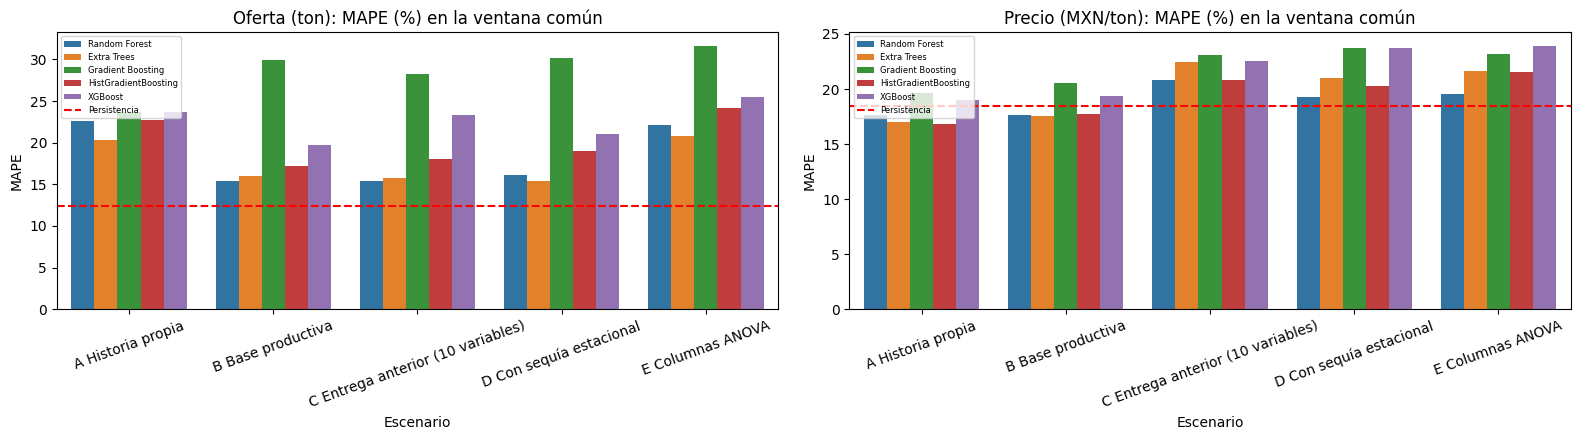

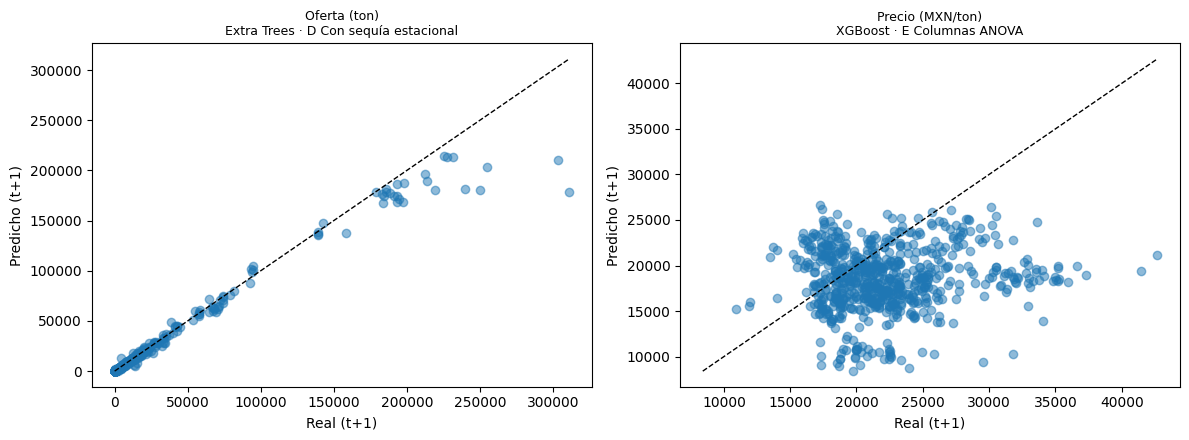

In [33]:
# Tabla pedida Split · Method · MSE · R2 (prueba propia) y gráficas del mejor modelo
tabla_pedida = (resultados[resultados['Conjunto'] == 'prueba'][['Split', 'Escenario', 'Objetivo', 'Method', 'MSE', 'R2']])
for obj in OBJETIVOS:
    print(f'\n=== {obj} · conjunto de PRUEBA ===')
    display(tabla_pedida[tabla_pedida['Objetivo'] == obj].drop(columns='Objetivo')
            .sort_values(['Split', 'Escenario', 'MSE']).reset_index(drop=True)
            .style.format({'MSE': '{:,.4g}', 'R2': '{:.3f}'}))
tabla_pedida.to_csv(SALIDAS2 / 'tabla_split_method_mse_r2.csv', index=False, encoding='utf-8-sig')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, obj in zip(axes, OBJETIVOS):
    d = resultados[(resultados['Conjunto'] == 'prueba_comun') & (resultados['Objetivo'] == obj) & (resultados['Method'] != 'Persistencia')]
    sns.barplot(data=d, x='Escenario', y='MAPE', hue='Method', ax=ax, errorbar=None)
    p = resultados[(resultados['Conjunto'] == 'prueba_comun') & (resultados['Objetivo'] == obj) & (resultados['Method'] == 'Persistencia')]['MAPE'].mean()
    ax.axhline(p, color='red', ls='--', label='Persistencia')
    ax.set_title(f'{obj}: MAPE (%) en la ventana común'); ax.tick_params(axis='x', rotation=20); ax.legend(fontsize=6)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, obj in zip(axes, OBJETIVOS):
    r = elegidos_propia[(elegidos_propia['Split'] == MEJOR_SPLIT_ETIQ) & (elegidos_propia['Objetivo'] == obj)].iloc[0]
    tr, te = TRAIN_TEST[MEJOR_SPLIT]
    tgt, _ = OBJETIVOS[obj]
    cols = ESCENARIOS[r['Escenario']](obj, MEJOR_SPLIT)
    yhat = AJUSTADOS[(MEJOR_SPLIT, r['Escenario'], obj)][r['Method']].predict(prep_X(te, cols))
    ax.scatter(te[tgt], yhat, alpha=0.5)
    lim = [min(te[tgt].min(), yhat.min()), max(te[tgt].max(), yhat.max())]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlabel('Real (t+1)'); ax.set_ylabel('Predicho (t+1)')
    ax.set_title(f"{obj}\n{r['Method']} · {r['Escenario']}", fontsize=9)
plt.tight_layout(); plt.show()

### 17.2 Control: variables de clima medido (2020 en adelante)

Aquí se prueba si la temperatura y la lluvia medidas en cada estado aportan algo. Se hace en un **universo corto** (solo años con clima medido) y comparando dos escenarios sobre **exactamente las mismas filas**: sin clima medido y con clima medido.

Con tan pocos años (las particiones dejan 1 o 2 años de prueba) y con clima que toma un solo valor por estado y año, **el resultado es exploratorio y no se debe usar para concluir**. Sirve para saber si hay una señal fuerte (que habría que seguir persiguiendo cuando haya más años) o ninguna.

In [34]:
if df_clima_jm_anual is not None and all(c in panel.columns for c in CLIMA_MEDIDO):
    u_c = universo.dropna(subset=CLIMA_MEDIDO).copy()
    print(f'Universo con clima medido: {len(u_c)} filas | años del objetivo: {sorted(u_c.periodo_obj.unique().tolist())}')
    if u_c['periodo_obj'].nunique() >= 4:
        filas_c = []
        for f in SPLITS:
            tr_c, te_c, c_c = split_temporal(u_c, f)
            etiqueta = f'{int(f * 100)}/{int(round((1 - f) * 100))}'
            print(f'   {etiqueta}: entrena hasta {c_c} ({len(tr_c)} filas) | prueba {c_c + 1}–{int(te_c.periodo_obj.max())} ({len(te_c)} filas)')
            for esc, cols_f in [('F0 sin clima medido', lambda o: BASE + CLIMA_ANUAL + CLIMA_ESTACIONAL),
                                ('F1 con clima medido', lambda o: BASE + CLIMA_ANUAL + CLIMA_ESTACIONAL + CLIMA_MEDIDO)]:
                for obj in OBJETIVOS:
                    res, _ = evaluar(tr_c, te_c, cols_f(obj), obj, esc, etiqueta)
                    filas_c += res
        res_c = pd.DataFrame(filas_c)
        res_c.to_csv(SALIDAS2 / 'resultados_clima_medido_exploratorio.csv', index=False, encoding='utf-8-sig')
        t = res_c[(res_c['Conjunto'] == 'prueba') & (res_c['Method'] != 'Persistencia')]
        mejor = t.loc[t.groupby(['Split', 'Objetivo', 'Escenario'])['cv_error'].idxmin()]
        display(mejor[['Split', 'Objetivo', 'Escenario', 'Method', 'MAPE', 'RMSE', 'R2']].sort_values(['Objetivo', 'Split', 'Escenario']).round(3))
        print('Compara F0 contra F1 con el mismo Split y Objetivo. Con este número de años, diferencias de pocos puntos no son concluyentes.')
    else:
        print('Hay menos de 4 años de objetivo con clima medido: no alcanza ni para un control exploratorio.')
else:
    print('Sin clima medido en el panel: control omitido.')

Universo con clima medido: 557 filas | años del objetivo: [2021, 2022, 2023, 2024]
   60/40: entrena hasta 2022 (275 filas) | prueba 2023–2024 (282 filas)
   70/30: entrena hasta 2023 (414 filas) | prueba 2024–2024 (143 filas)


,Split,Objetivo,Escenario,Method,MAPE,RMSE,R2
3,60/40,Oferta (ton),F0 sin clima medido,Extra Trees,13.008,10409.457,0.953
27,60/40,Oferta (ton),F1 con clima medido,Extra Trees,13.045,10320.649,0.953
51,70/30,Oferta (ton),F0 sin clima medido,Extra Trees,11.017,3747.366,0.992
75,70/30,Oferta (ton),F1 con clima medido,Extra Trees,10.937,3699.442,0.993
15,60/40,Precio (MXN/ton),F0 sin clima medido,Extra Trees,16.964,4309.770,-0.057
39,60/40,Precio (MXN/ton),F1 con clima medido,Extra Trees,15.471,4025.405,0.078
65,70/30,Precio (MXN/ton),F0 sin clima medido,Gradient Boosting,13.066,3899.462,-0.103
87,70/30,Precio (MXN/ton),F1 con clima medido,Extra Trees,12.735,3410.417,0.156


Compara F0 contra F1 con el mismo Split y Objetivo. Con este número de años, diferencias de pocos puntos no son concluyentes.


In [36]:
# Qué variables usa el modelo elegido (importancia por permutación en la prueba: cuánto empeora el error si se desordena cada variable)
for obj in OBJETIVOS:
    r = elegidos_propia[(elegidos_propia['Split'] == MEJOR_SPLIT_ETIQ) & (elegidos_propia['Objetivo'] == obj)].iloc[0]
    tr, te = TRAIN_TEST[MEJOR_SPLIT]
    tgt, _ = OBJETIVOS[obj]
    cols = ESCENARIOS[r['Escenario']](obj, MEJOR_SPLIT)
    mod = AJUSTADOS[(MEJOR_SPLIT, r['Escenario'], obj)][r['Method']]
    pi = permutation_importance(mod, prep_X(te, cols), te[tgt].values, n_repeats=5, random_state=SEMILLA,
                                scoring='neg_mean_absolute_percentage_error')
    imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)
    print(f"\n{obj} · {r['Method']} · {r['Escenario']}: importancia por permutación (aumento del MAPE al desordenar)")
    display(imp.round(4).to_frame('importancia'))
    imp.to_csv(SALIDAS2 / f"importancia_{'oferta' if obj.startswith('Oferta') else 'precio'}.csv", encoding='utf-8')


Oferta (ton) · Extra Trees · D Con sequía estacional: importancia por permutación (aumento del MAPE al desordenar)


,importancia
volumen,2.8638
sembrada_ha,1.2532
volumen_lag1,0.4899
rendimiento_ton_ha,0.0043
ciclon_meses,0.0011
sequia_lag1,0.0008
sequia_sev_media_anual,0.0002
precio_kg,0.0001
precio_lag1,-0.0000
sequia_max,-0.0003



Precio (MXN/ton) · XGBoost · E Columnas ANOVA: importancia por permutación (aumento del MAPE al desordenar)


,importancia
sequia_lag1,0.0021
precio_kg,0.0014
sequia_secas,0.0014
rendimiento_ton_ha,0.0006
precio_lag1,0.0004
volumen,-0.0005
ciclon_meses,-0.0007
sequia_max,-0.0056
sequia_sev_media_anual,-0.0062
sequia_cambio,-0.0093


## 19. Diccionario de datos

Funciones de la primera entrega. Describen cada tabla que usa el modelo.

In [37]:
def explorar_df(df, nombre, max_categorias=8):
    print(f"\n{'='*70}\n{nombre}  ->  {df.shape[0]:,} filas x {df.shape[1]} columnas\n{'='*70}")

    resumen = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos_%": (df.isna().mean() * 100).round(1),
        "valores_unicos": df.nunique(),
    })
    display(resumen)

    numericas = df.select_dtypes(include="number").columns
    if len(numericas) > 0:
        print("-- Rangos de columnas numéricas (min / media / max) --")
        display(df[numericas].describe().T[["min", "mean", "max"]].round(2))

    categoricas = df.select_dtypes(include="object").columns
    for col in categoricas:
        if df[col].nunique() <= max_categorias:
            print(f"-- Categorías de '{col}' --")
            print(df[col].value_counts(dropna=False).to_dict())

In [38]:
dataframes = {
    "df_siap": df_siap,
    "df_oferta": df_oferta,
    "df_tipo_cambio": df_tipo_cambio,
    "df_sequia_mensual": df_sequia_mensual,
    "df_ciclon_mensual": ciclon_mensual,
    "df_desastres_mensual": desastres_mensual,
    "df_clima_jm_mensual": df_clima_jm_mensual,
    "df_clima_jm_anual": df_clima_jm_anual,
    "df_destinos_2022": df_destinos,
    "df_origenes_2022": df_origenes,
    "df_exportaciones_mx_2025": df_exportaciones_mx,
    "panel": panel,
}
dataframes = {k: v for k, v in dataframes.items() if v is not None}

for nombre, df in dataframes.items():
    explorar_df(df, nombre)


df_siap  ->  793,769 filas x 26 columnas


,tipo,nulos_%,valores_unicos
Anio,float64,0.0,22
Idestado,float64,0.0,32
Nomestado,object,0.0,33
Idddr,float64,0.0,191
Nomddr,object,0.0,191
Idcader,float64,0.0,19
Nomcader,object,0.0,679
Idmunicipio,float64,0.0,570
Nommunicipio,object,0.0,2314
Idciclo,float64,0.0,3


-- Rangos de columnas numéricas (min / media / max) --


,min,mean,max
Anio,2003.0,2013.51,2.024000e+03
Idestado,1.0,18.42,3.200000e+01
Idddr,1.0,99.50,1.930000e+02
Idcader,1.0,2.69,1.900000e+01
Idmunicipio,1.0,79.65,5.700000e+02
Idciclo,1.0,2.04,3.000000e+00
Idmodalidad,1.0,1.46,2.000000e+00
Idunidadmedida,200201.0,200201.05,2.002170e+05
Idcultivo,1000000.0,7408909.84,1.507000e+07
Sembrada,0.0,588.15,2.165483e+05


-- Categorías de 'Nomcicloproductivo' --
{'Primavera-Verano': 341653, 'Perennes': 243773, 'Otoño-Invierno': 208343}
-- Categorías de 'Nommodalidad' --
{'Riego': 431053, 'Temporal': 362716}
-- Categorías de 'Nomunidad' --
{'Tonelada': 782571, 'Gruesa': 5574, 'Planta': 2152, 'Miles de lts.': 1830, 'Manojo': 1370, 'Metro cuadrado': 272}
-- Categorías de 'Nivel' --
{'Municipio': 793769}

df_oferta  ->  2,594 filas x 8 columnas


,tipo,nulos_%,valores_unicos
clave_mun,object,0.0,158
anio,int64,0.0,22
volumen,float64,0.0,2000
cosechada_ha,float64,0.0,792
sembrada_ha,float64,0.0,828
valor_miles,float64,0.0,2324
rendimiento_ton_ha,float64,6.0,1545
precio_kg,float64,6.0,1939


... (39 outputs left out)

,tipo,nulos_%,valores_unicos
clave_mun,object,0.0,158
anio,int64,0.0,22
volumen,float64,0.0,2000
cosechada_ha,float64,0.0,792
sembrada_ha,float64,0.0,828
valor_miles,float64,0.0,2324
rendimiento_ton_ha,float64,6.0,1545
precio_kg,float64,6.0,1939
sequia_sev_media_anual,float64,0.0,61
sequia_meses_severos,int64,0.0,9


-- Rangos de columnas numéricas (min / media / max) --


,min,mean,max
anio,2003.00,2.014680e+03,2.024000e+03
volumen,0.00,1.249606e+04,3.111428e+05
cosechada_ha,0.00,1.161090e+03,2.574000e+04
sembrada_ha,0.25,1.246420e+03,2.581500e+04
valor_miles,0.00,2.136337e+08,6.103480e+09
rendimiento_ton_ha,0.50,9.740000e+00,2.975000e+01
precio_kg,1000.00,1.592741e+04,4.268193e+04
sequia_sev_media_anual,0.00,1.090000e+00,3.750000e+00
sequia_meses_severos,0.00,1.250000e+00,8.000000e+00
ciclon_meses,1.00,3.450000e+00,7.000000e+00


-- Categorías de 'clave_estado' --
{'14': 1448, '16': 1146}
-- Categorías de 'estado' --
{'Jalisco': 1448, 'Michoacán': 1146}


In [39]:
def construir_diccionario(df, nombre_tabla):
    return pd.DataFrame({
        "tabla":          nombre_tabla,
        "columna":        df.columns,
        "tipo":           df.dtypes.astype(str).values,
        "pct_nulos":      (df.isna().mean() * 100).round(2).values,
        "valores_unicos": df.nunique().values,
        "ejemplo":        [df[c].dropna().iloc[0] if df[c].notna().any() else None
                            for c in df.columns],
    })

diccionario_datos = pd.concat(
    [construir_diccionario(df, nombre) for nombre, df in dataframes.items()],
    ignore_index=True,
)
display(diccionario_datos)
diccionario_datos.to_csv("diccionario_datos.csv", index=False)

,tabla,columna,tipo,pct_nulos,valores_unicos,ejemplo
0,df_siap,Anio,float64,0.00,22,2003.0
1,df_siap,Idestado,float64,0.00,32,1.0
2,df_siap,Nomestado,object,0.00,33,Aguascalientes
3,df_siap,Idddr,float64,0.00,191,1.0
4,df_siap,Nomddr,object,0.00,191,Aguascalientes
...,...,...,...,...,...,...
126,panel,sequia_lluvias,float64,0.00,13,0.333333
127,panel,sequia_secas,float64,0.00,13,1.0
128,panel,sequia_max,float64,0.00,6,1.0
129,panel,sequia_lag1,float64,6.59,61,0.5


## 20. Llaves de enlace entre dataframes

Cómo se unen las tablas. Se actualizó respecto a la primera entrega, porque ahora la unidad es municipio × año.

In [40]:
llaves = pd.DataFrame([
    ("df_oferta",   "clave_mun + anio",     "df_sequia_mensual",   "clave_mun + anio + mes",   "uno a muchos (se agrega a año)",   "confirmada"),
    ("df_oferta",   "clave_mun → estado",   "df_ciclon_mensual",   "clave_estado + anio + mes", "uno a muchos (se agrega a año)",   "confirmada; aproximada por caja costera"),
    ("df_oferta",   "clave_mun → estado",   "df_desastres_mensual","clave_estado + anio + mes", "uno a muchos (se agrega a año)",   "confirmada; asignación por texto"),
    ("df_oferta",   "anio",                 "df_tipo_cambio",      "anio",                     "muchos a uno (promedio anual)",    "confirmada"),
    ("df_oferta",   "clave_mun → estado + anio", "df_clima_jm_anual", "clave_estado + anio", "muchos a uno (mismo clima para todos los municipios del estado)", "confirmada; solo 2020+"),
    ("df_destinos_2022", "pais", "df_exportaciones_mx_2025", "socio", "por nombre de país (no hay llave numérica compartida)", "pendiente: los nombres difieren (p. ej. Estados Unidos / Estados Unidos de América)"),
    ("df_siap",     "Idestado + Idmunicipio", "df_oferta",         "clave_mun (5 dígitos)",    "muchos a uno (agregado)",          "confirmada"),
    ("df_sequia_mensual", "clave_mun",      "Sequia.csv",          "CVE_CONCATENADA",          "uno a uno",                        "confirmada"),
], columns=["dataset_A", "col_A", "dataset_B", "col_B", "tipo_join", "estado"])
display(llaves)

,dataset_A,col_A,dataset_B,col_B,tipo_join,estado
0,df_oferta,clave_mun + anio,df_sequia_mensual,clave_mun + anio + mes,uno a muchos (se agrega a año),confirmada
1,df_oferta,clave_mun → estado,df_ciclon_mensual,clave_estado + anio + mes,uno a muchos (se agrega a año),confirmada; aproximada por caja costera
2,df_oferta,clave_mun → estado,df_desastres_mensual,clave_estado + anio + mes,uno a muchos (se agrega a año),confirmada; asignación por texto
3,df_oferta,anio,df_tipo_cambio,anio,muchos a uno (promedio anual),confirmada
4,df_oferta,clave_mun → estado + anio,df_clima_jm_anual,clave_estado + anio,muchos a uno (mismo clima para todos los munic...,confirmada; solo 2020+
5,df_destinos_2022,pais,df_exportaciones_mx_2025,socio,por nombre de país (no hay llave numérica comp...,pendiente: los nombres difieren (p. ej. Estado...
6,df_siap,Idestado + Idmunicipio,df_oferta,clave_mun (5 dígitos),muchos a uno (agregado),confirmada
7,df_sequia_mensual,clave_mun,Sequia.csv,CVE_CONCATENADA,uno a uno,confirmada


## 21. Agente de IA (Gemini)

Código PENDIENTE A DESARROLLAR (`GEMINI_API_KEY`).

Esto se implementará en siguientes pasos pasos pero contamos con la configuración a continuación.

# Agente de IA

Nombre: API TEC
Clave API: Privado
Nombre del proyecto: projects/617685196179


Curl: curl "https://generativelanguage.googleapis.com/v1beta/models/gemini-flash-latest:generateContent" \
  -H 'Content-Type: application/json' \
  -H 'X-goog-api-key: AQ.
  -X POST \
  -d '{
    "contents": [
      {
        "parts": [
          {
            "text": "Explain how AI works in a few words"
          }
        ]
      }
    ]
  }'

In [41]:
!pip install langchain langchain_google_genai langgraph langchain-community -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.0.0 which is incompatible.


In [42]:
pip install langchain-google-genai

In [43]:
import os
import warnings

# 1. Silenciar advertencias de parámetros fijos de Gemini
warnings.filterwarnings("ignore", category=UserWarning, module="langchain_google_genai")

# 2. Configuración de IPython e inicialización de la API Key
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from google.colab import userdata
os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")

# 3. Importar el modelo y el extractor de texto limpio
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.output_parsers import StrOutputParser

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    temperature=0.4
)

chain = llm | StrOutputParser()

# Invocamos la cadena completa
response_text = chain.invoke("Explica la relación entre la producción de aguacate y el clima")
print(response_text)


SecretNotFoundError: Secret GOOGLE_API_KEY does not exist.

In [ ]:
!pip install ddgs
!pip install duckduckgo-search

In [ ]:
pip install langchain-community

In [ ]:
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper
from langchain_community.tools import DuckDuckGoSearchRun

# Limit results to 3 so the agent doesn't get overwhelmed
wrapper = DuckDuckGoSearchAPIWrapper(max_results=2)

# Use SearchRun (not SearchResults) for cleaner agent observations
ddg_search = DuckDuckGoSearchRun(
                        api_wrapper=wrapper,
                        name="web_search",
                        description="Search the web using DuckDuckGo. Use this for recent events, news, or general questions.",
)

# Test the search tool

from datetime import datetime

fecha_hoy = datetime.now().strftime("%Y-%m-%d")

query = f"Cuáles son las noticias más importantes de los últimos 3 meses respecto a la industria aguacatera? Hoy es {fecha_hoy}"

results = ddg_search.invoke(query)
print(results)


> ⚠️ **Texto de la entrega anterior.** Esta sección se redactó con los resultados de la corrida anterior (Random Forest, partición 70/15/15, con clima de EE.UU. disponible pero descartado por cobertura). Debe reescribirse con los resultados de las secciones 14 a 18 de esta versión antes de entregar.

## 22. Justificación de técnicas


**Unidad municipio × año.** El SIAP publica la producción por ciclo agrícola y año, no por mes. Repetir un valor anual dentro de cada mes no le aporta variación real al modelo, así que la unidad es municipio × año. El documento de estrategia pedía municipio × mes; eso exige una fuente de producción mensual que hoy no tenemos.

**Dos objetivos con las mismas variables.** Oferta (volumen) y precio medio rural son los dos resultados que pide el reto. Usar las mismas variables de entrada permite comparar cuál de los dos responde mejor al clima.

**Validación temporal.** En una serie de tiempo, una división aleatoria deja que el modelo vea el futuro y sobreestima su desempeño. La división es por año del objetivo: entrenamiento, después validación, después prueba. Con un objetivo de t+1, ninguna fila de entrenamiento usa valores que caen en la validación.

**Persistencia como referencia.** Un modelo que no supera "el año que viene será igual que este" no aporta valor práctico. Por eso cada resultado se compara contra esa referencia.

**Random Forest.** Con pocos años por municipio, una red recurrente tendría muy pocas observaciones. Random Forest funciona bien con relaciones no lineales y da importancias de variables. *Conocimiento general, no verificado con estos datos:* XGBoost es una alternativa razonable para probar después.

**Cobertura mínima.** Una variable con menos de 50% de datos se descarta. Así el modelo no aprende de valores rellenados en exceso. Hoy se descartan la seguridad (solo hay 2026) y, para el modelo anual, el tipo de cambio (solo se traslapa con 2022–2024).

**Índices con z-scores.** Ponen en la misma escala variables con unidades distintas. Los pesos son iguales, que es el punto de partida más transparente.

**Probabilidad de caída por dispersión de árboles.** Es una aproximación explicable. Para una probabilidad calibrada se necesitarían intervalos de predicción, que quedan como siguiente paso.

**Gen AI para noticias y recomendaciones en el momento (siguiente etapa).** El modelo solo conoce las tablas históricas y el SIAP se publica con meses de retraso, así que se plantea usar Gemini como una capa que se mantiene al día. Buscaría noticias de aguacate (precios, sequías, plagas, inseguridad, aranceles, tipo de cambio) y las convertiría en eventos con fecha, lugar e intensidad, que entran al modelo como variables nuevas solo si se publicaron antes de la fecha a predecir. La predicción la sigue haciendo el modelo con nuestros datos, y las variables nuevas se conservan únicamente si mejoran frente a la persistencia. Gemini lee las salidas del modelo y las noticias del día para dar una recomendación según el perfil de quien consulta.

> ⚠️ **Texto de la entrega anterior.** Esta sección se redactó con los resultados de la corrida anterior (Random Forest, partición 70/15/15, con clima de EE.UU. disponible pero descartado por cobertura). Debe reescribirse con los resultados de las secciones 14 a 18 de esta versión antes de entregar.

## 23. Interpretación de hallazgos

Michoacán y Jalisco concentran cerca del 80% del aguacate del país, y Michoacán produce unas seis veces más que Jalisco (2.0 millones de toneladas contra 0.34 en 2024). La producción nacional se triplicó entre 2003 y 2023, de 0.9 a 2.97 millones de toneladas, y en 2024 bajó 7%. Las sequías fuertes de 2021, 2023 y 2024 no frenaron esa tendencia, así que a largo plazo el clima no parece ser lo que mueve la oferta. La caída de 2024 podría venir de la sequía de 2023, pero los datos no alcanzan para afirmarlo: en 2010 la producción también bajó y ese año casi no hubo sequía.

En el periodo de prueba (2022–2024) ningún modelo le gana a repetir el valor del año anterior. En oferta el error es de 17.4% contra 10.4% de repetir el dato. En precio, 19.3% contra 18.5%. La oferta del año siguiente depende casi por completo de la superficie sembrada y de la producción actual, y el clima pesa menos de 1%. En el precio el clima pesa algo más, cerca de 13%, pero el modelo casi siempre predice entre \$15,000 y \$25,000 por tonelada y no llega a los precios altos. Además, en 2023 el precio nacional bajó de unos $25,000 a unos \$20,000 por tonelada, un salto que un modelo entrenado con datos de 2005 a 2018 no podía anticipar.

Para 2025 se espera que el precio en Michoacán sea de unos \$19,100 por tonelada (1.9% menos que en 2024) con una oferta cercana a 2.0 millones de toneladas. En Jalisco el modelo prevé una baja de 14%, de \$23,261 a \$19,929, pero probablemente sea el modelo regresando al promedio y no una señal real del mercado. Entre municipios, Ario, Salvador Escalante y Tacámbaro tienen entre 94% y 95% de probabilidad de caída de precio, mientras que Tancítaro, Peribán y Los Reyes están entre 25% y 34%.

Para el exportador, el tipo de cambio importa más que el pronóstico. Con el promedio de 2024 (18.3 pesos por dólar), una tonelada de Michoacán vale unos 1,040 dólares. Como en 2024 el peso fue de 16.4 a 20.8, ese mismo precio en pesos equivale a entre 930 y 1,160 dólares según el momento.

Los 15 municipios con más riesgo climático son todos de Michoacán, encabezados por Hidalgo, Tuzantla y Queréndaro, y el riesgo viene sobre todo de la sequía. Los grandes productores como Tancítaro y Uruapan tienen un riesgo medio. Un riesgo climático alto tampoco implica un volumen inestable: Queréndaro varía mucho de un año a otro (CV de 1.28), pero Jungapeo y Morelos casi no varían (0.39 y 0.24) aunque tengan riesgo alto. Este análisis no incluye seguridad, porque los datos de delitos solo cubren 2026.

Por lo tanto, en conclusión, con estos datos lo más razonable para fijar un precio es iniciar con el precio actual con un margen de error. El modelo nos va a servir para comparar el riesgo entre municipios, no para dar una cifra exacta. Para mejorarlo hacen falta los delitos de 2015 a 2025, una serie más larga de tipo de cambio y datos de producción y precio mensuales.

In [ ]:
SALIDAS = DATA_DIR / 'salidas'
SALIDAS.mkdir(parents=True, exist_ok=True)
panel.to_csv(SALIDAS / 'panel_municipio_anio.csv', index=False)
productor.to_csv(SALIDAS / 'salida_productor.csv', index=False)
exportador.to_csv(SALIDAS / 'salida_exportador.csv', index=False)
comercial.to_csv(SALIDAS / 'salida_comercializador.csv', index=False)
inversionista.to_csv(SALIDAS / 'salida_inversionista.csv', index=False)
cobertura.to_csv(SALIDAS / 'cobertura_fuentes.csv', index=False)
if df_clima_jm_anual is not None:
    df_clima_jm_anual.to_csv(SALIDAS / 'clima_jalisco_michoacan_anual.csv', index=False)
for _nombre, _df in [('mercado_destinos_2022', df_destinos), ('mercado_origenes_2022', df_origenes),
                     ('exportaciones_mx_2025', df_exportaciones_mx)]:
    if _df is not None:
        _df.to_csv(SALIDAS / f'{_nombre}.csv', index=False)
print('Las salidas de las secciones 14 a 18 están en', DATA_DIR / 'salidas_evidencia2')
print('Archivos guardados en', SALIDAS)
print(sorted(p.name for p in SALIDAS.iterdir()))

if GUARDAR_EN_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount('/content/drive')
    destino = Path('/content/drive/MyDrive/RETO_AGUACATE_salidas')
    shutil.copytree(SALIDAS, destino, dirs_exist_ok=True)
    print('Copiado a Drive:', destino)

## 24. Diagrama Entidad-Relación

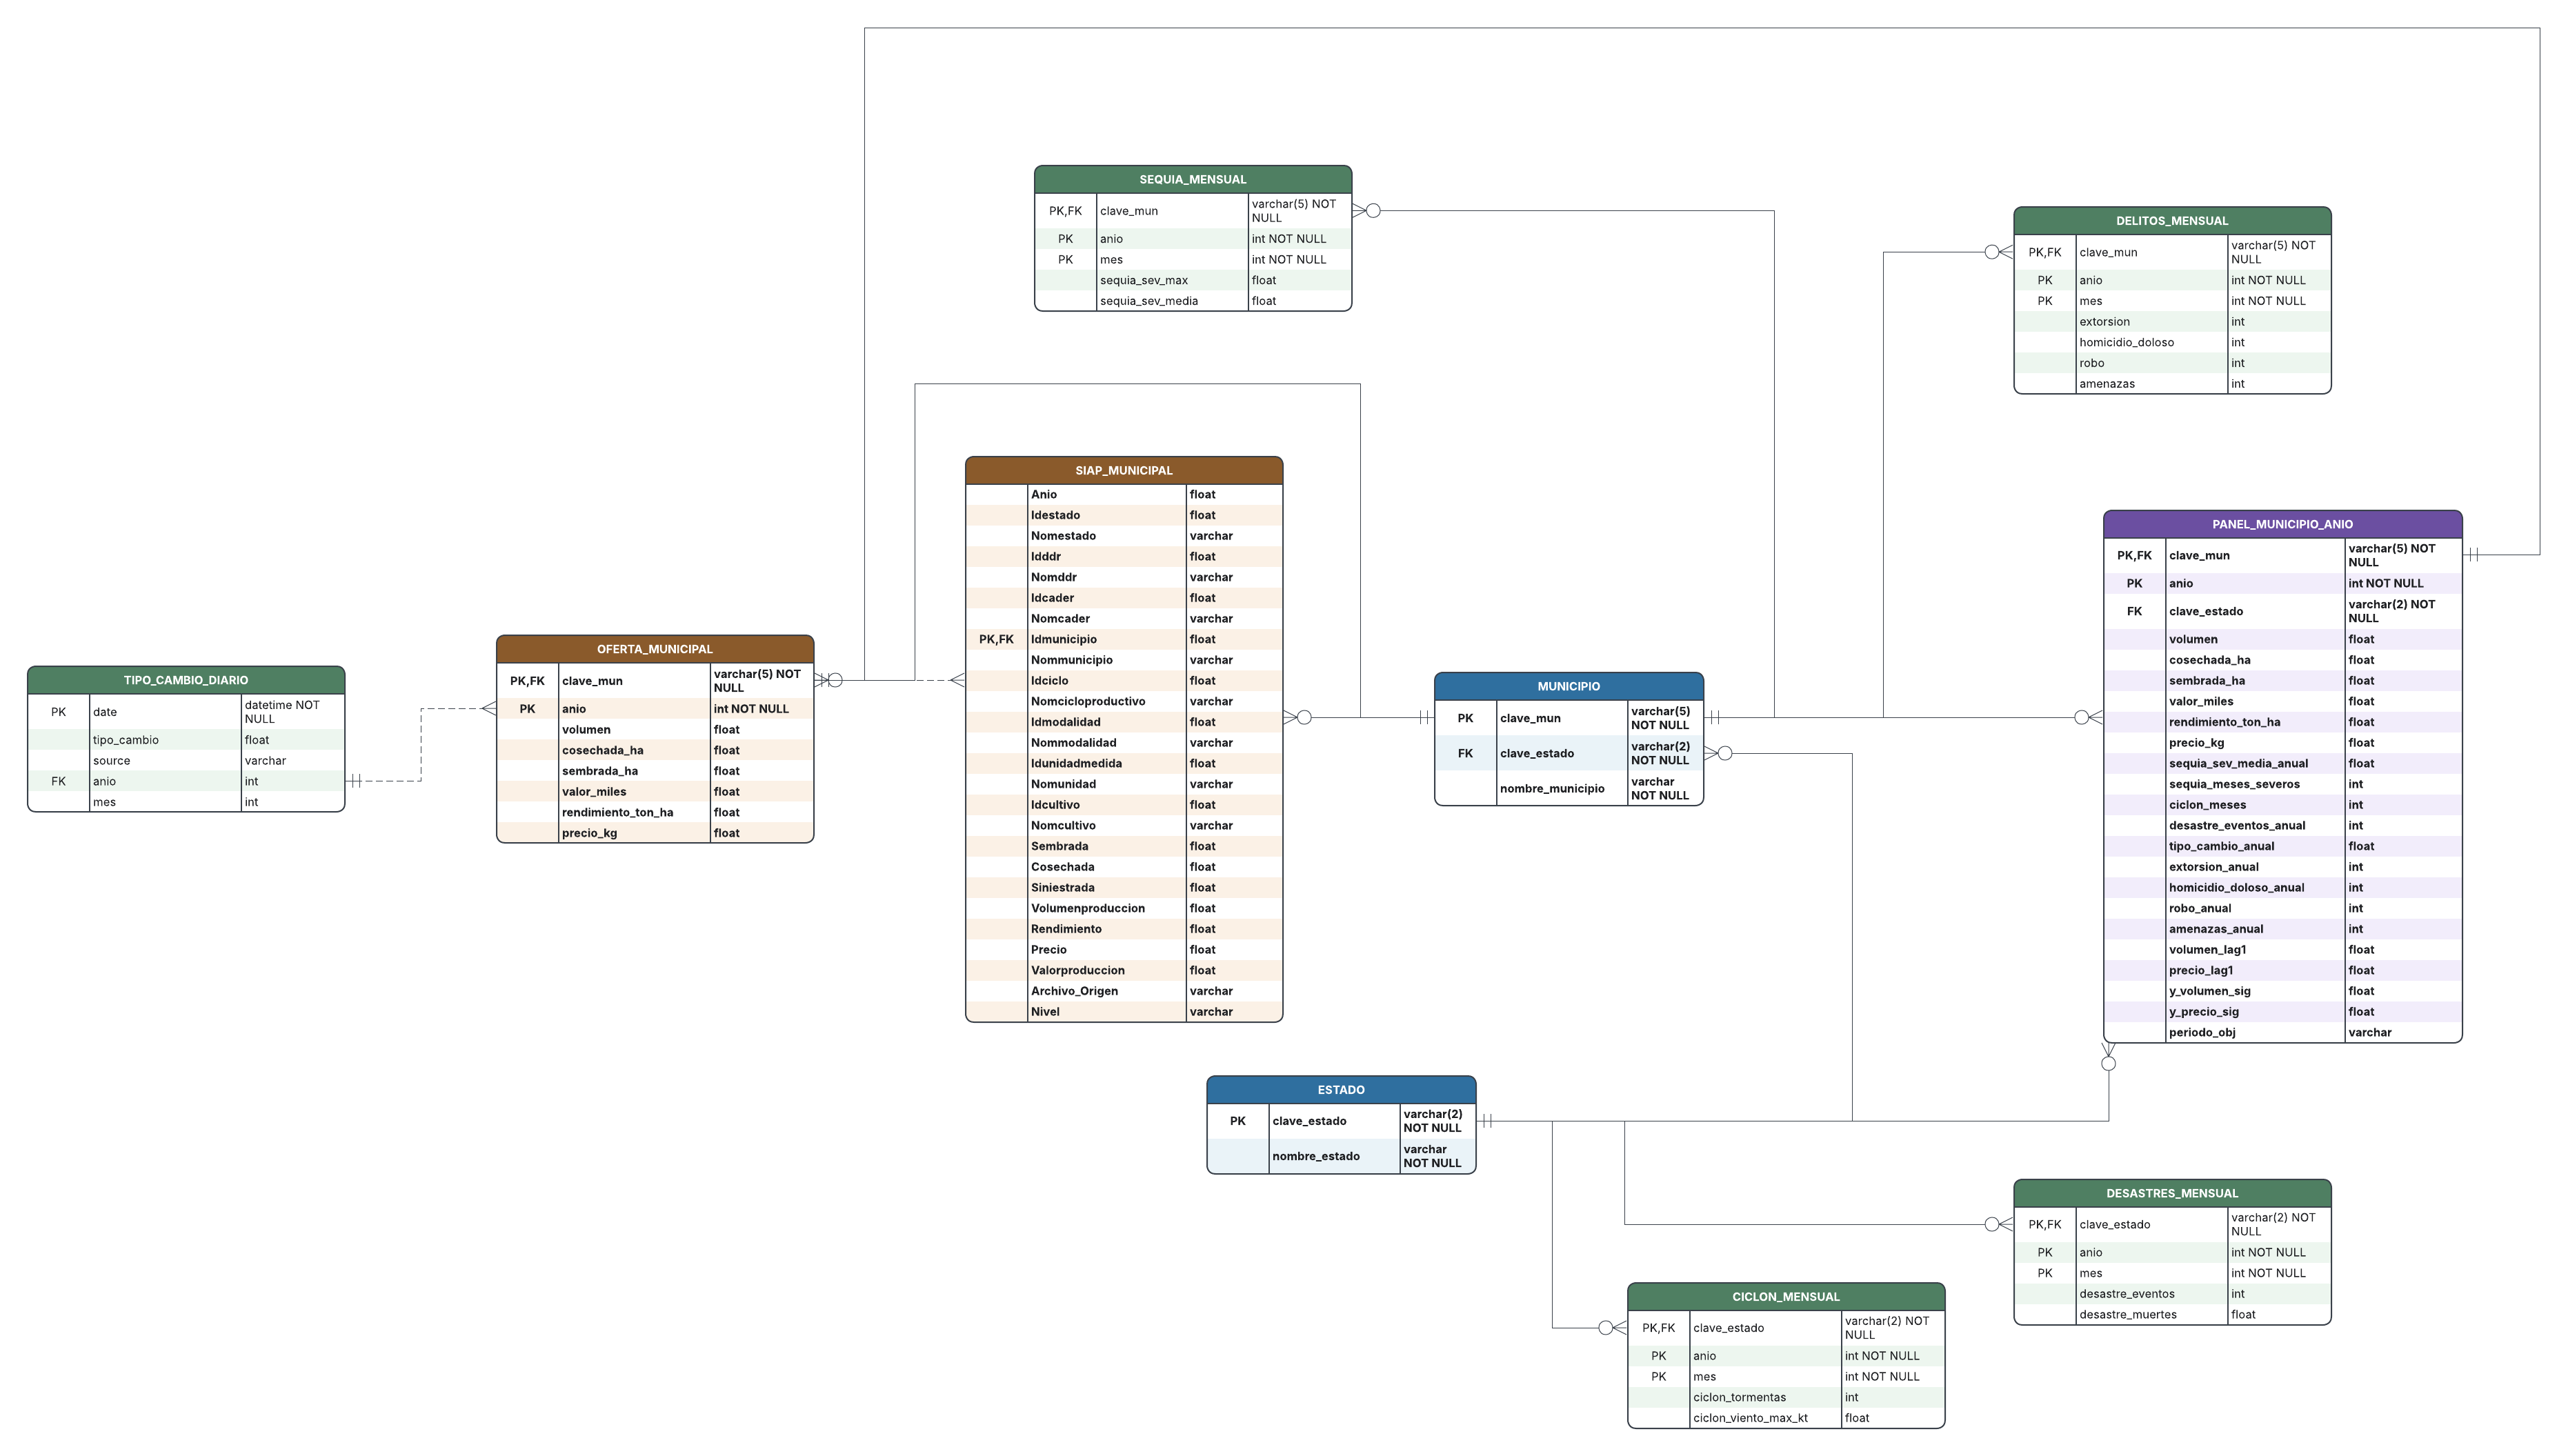